In [1]:
!pip install lasio

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lasio
NULL_CANDIDATES = [-9999, -999.25]

In [3]:
LAS_PATH = 'IITB_GS535_TestDataset.las'
las = lasio.read(LAS_PATH)

print("Well name :", las.well["WELL"].value)
print("Null value:", las.well["NULL"].value)
print("Start/Stop/Step (m):", las.well["STRT"].value, las.well["STOP"].value, las.well["STEP"].value)

print("\nCurves in the file:")
for curve in las.curves:
    print(f"  {curve.mnemonic:6s} ({curve.unit:7s}) : {curve.descr}")

Well name : IITB_GS535
Null value: -9999
Start/Stop/Step (m): 2153 2416.9568 0.1524

Curves in the file:
  MD     (m      ) : {F}
  DTCO   (us/ft  ) : Delta-T Comp - P & S {F}
  DTSM   (us/ft  ) : Delta-T Shear - P & S {F}
  GR     (gAPI   ) : Gamma-Ray SC Calibrated {F}
  HCAL   (in     ) : HRCC Cal. caliper SC {F}
  LLD    (ohm.m  ) : DEEP RESISTIVITY {F}
  LLS    (ohm.m  ) : SHALLOW RESISTIVITY {F}
  NPHI   (m3/m3  ) : Thermal Neutron Porosity (Ratio Method) {F}
  RHOB   (g/cm3  ) : {F}


In [4]:
df = las.df().reset_index()
df = df.rename(columns={df.columns[0]: "DEPTH"})   # first column is the depth curve (MD)
df.head()

,DEPTH,DTCO,DTSM,GR,HCAL,LLD,LLS,NPHI,RHOB
0,2153.0000,53.58000,98.76900,51.97200,8.973000,67.650002,50.33401,0.021000,2.668344
1,2153.1524,54.37169,98.23615,48.19945,8.961284,107.749496,72.05051,0.014952,2.655155
2,2153.3048,52.90863,99.32339,54.18253,8.961048,111.161400,71.38699,0.013000,2.655155
3,2153.4572,55.08701,102.91400,61.09183,8.963717,105.731400,66.09981,0.013000,2.655155
4,2153.6096,54.99302,103.67820,64.04803,8.967384,105.045403,63.60770,0.013000,2.654997


In [5]:
for v in NULL_CANDIDATES:
    print(f"Samples equal to {v}:")
    print((df == v).sum().to_string(), "\n")

df = df.replace(NULL_CANDIDATES, np.nan)     # safety net (lasio normally does this already)

print("NaN count per curve after cleaning:")
print(df.isna().sum().to_string())

Samples equal to -9999:
DEPTH    0
DTCO     0
DTSM     0
GR       0
HCAL     0
LLD      0
LLS      0
NPHI     0
RHOB     0 

Samples equal to -999.25:
DEPTH    0
DTCO     0
DTSM     0
GR       0
HCAL     0
LLD      0
LLS      0
NPHI     0
RHOB     0 

NaN count per curve after cleaning:
DEPTH    0
DTCO     0
DTSM     0
GR       0
HCAL     0
LLD      0
LLS      0
NPHI     0
RHOB     0


In [6]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (1733, 9)


In [7]:
df.head()

,DEPTH,DTCO,DTSM,GR,HCAL,LLD,LLS,NPHI,RHOB
0,2153.0000,53.58000,98.76900,51.97200,8.973000,67.650002,50.33401,0.021000,2.668344
1,2153.1524,54.37169,98.23615,48.19945,8.961284,107.749496,72.05051,0.014952,2.655155
2,2153.3048,52.90863,99.32339,54.18253,8.961048,111.161400,71.38699,0.013000,2.655155
3,2153.4572,55.08701,102.91400,61.09183,8.963717,105.731400,66.09981,0.013000,2.655155
4,2153.6096,54.99302,103.67820,64.04803,8.967384,105.045403,63.60770,0.013000,2.654997


In [8]:
df.describe().round(3)

,DEPTH,DTCO,DTSM,GR,HCAL,LLD,LLS,NPHI,RHOB
count,1733.000,1733.000,1733.000,1733.000,1733.000,1733.000,1733.000,1733.000,1733.000
mean,2284.978,60.498,115.424,39.967,8.758,75.167,39.897,0.058,2.585
std,76.264,6.219,11.073,10.233,0.136,131.851,68.938,0.059,0.075
min,2153.000,49.999,97.371,20.867,8.460,1.147,1.136,-0.002,2.326
25%,2218.989,56.491,107.655,32.652,8.644,20.209,9.664,0.016,2.540
50%,2284.978,58.998,112.668,38.397,8.743,35.561,17.626,0.042,2.592
75%,2350.968,62.789,119.582,44.802,8.869,75.137,40.443,0.084,2.642
max,2416.957,94.499,163.646,109.981,9.163,1928.892,898.042,0.432,2.814


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1733 entries, 0 to 1732
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DEPTH   1733 non-null   float64
 1   DTCO    1733 non-null   float64
 2   DTSM    1733 non-null   float64
 3   GR      1733 non-null   float64
 4   HCAL    1733 non-null   float64
 5   LLD     1733 non-null   float64
 6   LLS     1733 non-null   float64
 7   NPHI    1733 non-null   float64
 8   RHOB    1733 non-null   float64
dtypes: float64(9)
memory usage: 122.0 KB


In [10]:
depth = df["DEPTH"]
steps = np.diff(depth.values)

print(f"Depth range : {depth.min():.4f} - {depth.max():.4f} m  ({depth.max() - depth.min():.1f} m)")
print(f"Rows        : {len(df)}")
print(f"Sorted      : {depth.is_monotonic_increasing}")
print(f"Duplicates  : {depth.duplicated().sum()}")
print(f"Step (m)    : median {np.median(steps):.4f}, min {steps.min():.4f}, max {steps.max():.4f}")
print(f"Regular step: {np.allclose(steps, np.median(steps), atol=1e-4)}")

Depth range : 2153.0000 - 2416.9568 m  (264.0 m)
Rows        : 1733
Sorted      : True
Duplicates  : 0
Step (m)    : median 0.1524, min 0.1524, max 0.1524
Regular step: True


In [11]:
print("NPHI  min/max:", round(df.NPHI.min(), 3), "/", round(df.NPHI.max(), 3))
print("RHOB min/max:", round(df.RHOB.min(), 3), "/", round(df.RHOB.max(), 3))
print("HCAL min/max:", round(df.HCAL.min(), 3), "/", round(df.HCAL.max(), 3))

print("\nResistivity skewness (0 = symmetric):")
for c in ["LLD", "LLS"]:
    print(f"  {c}: raw {df[c].skew():6.2f}  ->  log10 {np.log10(df[c]).skew():5.2f}")

NPHI  min/max: -0.002 / 0.432
RHOB min/max: 2.326 / 2.814
HCAL min/max: 8.46 / 9.163

Resistivity skewness (0 = symmetric):
  LLD: raw   6.68  ->  log10  0.26
  LLS: raw   5.59  ->  log10  0.43


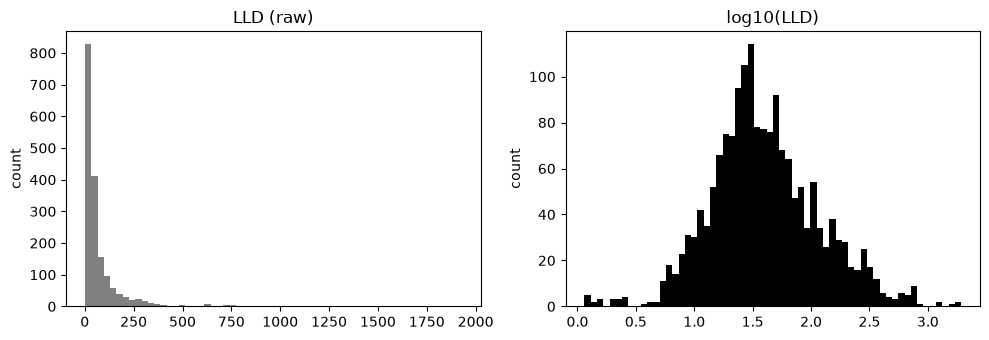

In [12]:
# Histograms of deep resistivity before and after the log transform
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(df.LLD, bins=60, color="gray");            ax[0].set_title("LLD (raw)")
ax[1].hist(np.log10(df.LLD), bins=60, color="black"); ax[1].set_title("log10(LLD)")
for a in ax: a.set_ylabel("count")
plt.tight_layout(); plt.show()

## 7. Answers to the Step 1A questions
- **Depth range / step / rows:** 2153.0 - 2416.9568 m, step 0.1524 m (regular), 1733 rows.
- **NPHI units:** a fraction (m3/m3), not percent: the maximum is about 0.43.
- **RHOB units:** g/cm3 (values 2.33 - 2.81, typical rock densities).
- **Resistivity choice:** LLD (deep). It reads farther into the formation and is less affected by mud invasion than LLS.
- **Nulls:** none remain after cleaning; `lasio` already converted the header null value (-9999) to NaN.
- **Skew:** LLD is strongly right-skewed (mean about twice the median, maximum about 1929 ohm.m), so we take log10 before Gaussian modelling.
- **Borehole:** HCAL stays between about 8.5 and 9.2 in, so the hole is close to in-gauge.


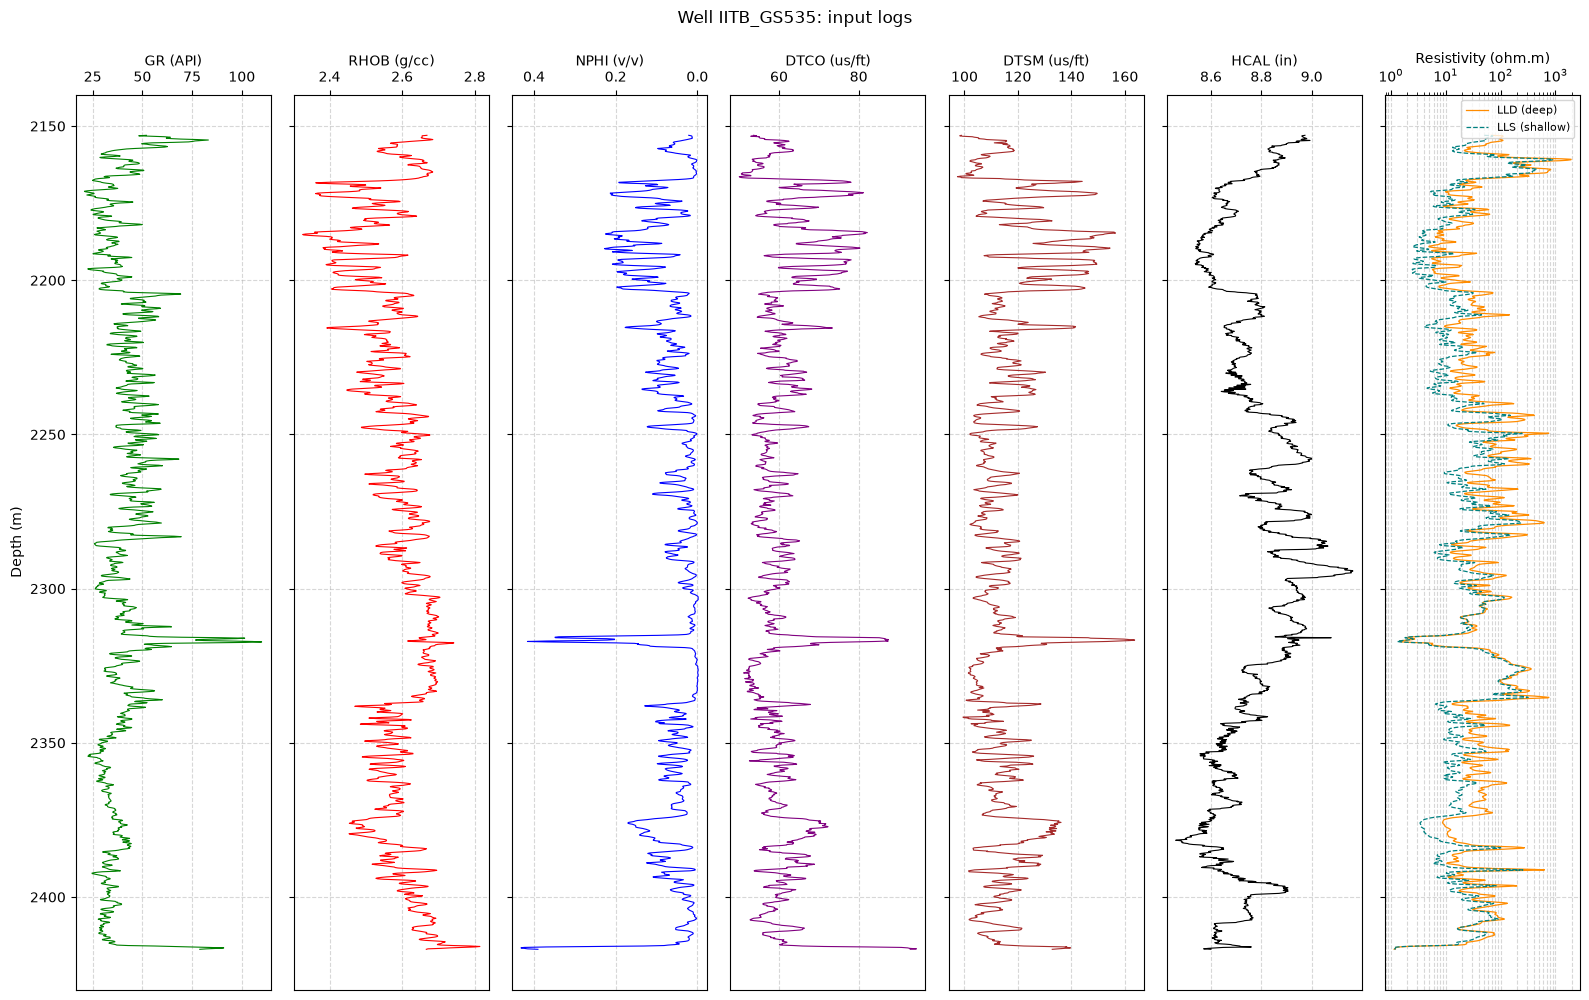

In [13]:
tracks = [
    ("GR",   "green",  "GR (API)"),
    ("RHOB", "red",    "RHOB (g/cc)"),
    ("NPHI", "blue",   "NPHI (v/v)"),
    ("DTCO", "purple", "DTCO (us/ft)"),
    ("DTSM", "brown",  "DTSM (us/ft)"),
    ("HCAL", "black",  "HCAL (in)"),
]

# one extra panel for the two resistivity curves
fig, axes = plt.subplots(nrows=1, ncols=len(tracks) + 1, figsize=(16, 10), sharey=True)
fig.suptitle("Well IITB_GS535: input logs", y=0.995)

# panels 1-6: one curve per panel
for ax, (col, color, label) in zip(axes[:len(tracks)], tracks):
    ax.plot(df[col], df["DEPTH"], color=color, linewidth=0.8)
    if col == "NPHI":
        ax.invert_xaxis()                      # high porosity on the left
    ax.set_xlabel(label)
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()

# panel 7: LLD and LLS together on a log axis (drawn once, outside the loop)
ax_res = axes[-1]
ax_res.semilogx(df["LLD"], df["DEPTH"], color="darkorange", linewidth=0.9, label="LLD (deep)")
ax_res.semilogx(df["LLS"], df["DEPTH"], color="teal", linewidth=0.9, linestyle="--", label="LLS (shallow)")
ax_res.set_xlabel("Resistivity (ohm.m)")
ax_res.grid(True, which="both", linestyle="--", alpha=0.5)
ax_res.xaxis.set_label_position("top")
ax_res.xaxis.tick_top()
ax_res.legend(loc="upper right", fontsize=8)

axes[0].set_ylabel("Depth (m)")
axes[0].invert_yaxis()                          # deeper = lower; shared by all panels

plt.tight_layout()
plt.savefig("tracks.png", dpi=150)              # save BEFORE show()
plt.show()

Observations

Overall: most of the well is tight, low-porosity rock. The median NPHI is about 0.04 and DTCO about 59 µs/ft, and RHOB stays between 2.4 and 2.8 g/cm³.

Two porous-looking zones at 2165–2205 and 2375–2386 m: lower RHOB, higher NPHI, slower DTCO and DTSM, and lower resistivity (LLD 12–16 against about 40 elsewhere).

GR does not tell the zones apart. The porous-looking zones have low GR (33–39), the same as the tight rock at 2386–2415 m (32).
GR correlates only weakly with the other curves (0.31 with RHOB, about 0 with NPHI, DTCO and DTSM). This is a good argument for using several features together.

Thin bed at ~2315–2319 m: GR peaks near 110, NPHI near 0.37, DTSM near 163, and LLD falls to about 1.5. RHOB does not drop, and the caliper does not change, so this is not a washout. It sits directly on top of the tightest zone (2319–2337 m), so the contrast is sharp. This is only 2–4 m thick, and it's the sort of bed the HMM must not smooth away.

Curve relationships: NPHI, DTCO and DTSM rise and fall together and RHOB moves the other way, so they carry mostly one porosity-like signal. LLD reads above LLS in 99% of samples (median ratio about 2.1), and the two curves almost coincide in the thin beds.

Ends of the log: at the very bottom (about 2415.9–2417 m) GR, NPHI and DTCO rise and LLD falls to about 1.2, like the 2317 m bed, but RHOB also climbs to 2.8. It could be real or an end-of-log effect, so decide how to treat it in Step 1C.

The top (about 2153–2158 m) has a GR rise to about 85.
Borehole: HCAL stays between 8.46 and 9.16 in, so the hole is in gauge. It is smallest (about 8.55) in the two porous-looking zones, with a correlation of −0.47 with NPHI.

 That is not a washout (a washout enlarges the hole and lowers RHOB). A possible reason is mud cake building up on porous rock, but treat that as a hypothesis, not a conclusion. There is also a single-sample caliper spike near 2315.9 m.

Caliper reference (median HCAL): 8.74 in, tolerance +/- 0.5 in
HCAL range: 8.46 - 9.16 in

              samples  percent
flag_missing        0     0.00
flag_range          0     0.00
flag_cali           0     0.00
flag_edge          10     0.58
flag               10     0.58

Range flags per curve:
flag_range_GR      0
flag_range_RHOB    0
flag_range_NPHI    0
flag_range_DTCO    0
flag_range_DTSM    0
flag_range_HCAL    0
flag_range_LLD     0
flag_range_LLS     0

Good samples: 1723 of 1733

Samples in flat runs (>= 5 identical consecutive values):
  GR    0
  RHOB  0
  NPHI  44
  DTCO  0
  DTSM  0
  HCAL  0
  LLD   0
  LLS   0


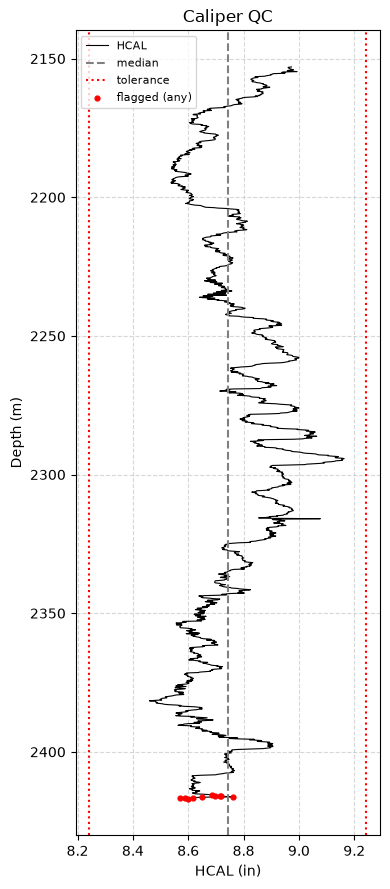

In [14]:
# ---------------- Step 1C: quality-control flags ----------------
CURVES = ["GR", "RHOB", "NPHI", "DTCO", "DTSM", "HCAL", "LLD", "LLS"]

RANGE = {                      # physically plausible (min, max); change and justify
    "GR":   (0, 300),          # gAPI
    "RHOB": (1.5, 3.2),        # g/cm3
    "NPHI": (-0.05, 0.8),      # v/v (tiny negatives are allowed)
    "DTCO": (40, 200),         # us/ft
    "DTSM": (70, 400),         # us/ft
    "HCAL": (6, 12),           # in
    "LLD":  (0.1, 10000),      # ohm.m
    "LLS":  (0.1, 10000),      # ohm.m
}
CALI_TOL_IN   = 0.5            # flag if |HCAL - median HCAL| exceeds this (inches)
EDGE_TOP_M    = 0.0            # metres at the top of the log to flag (0 = none)
EDGE_BOTTOM_M = 1.5            # metres at the bottom of the log to flag

# 1. missing values
df["flag_missing"] = df[CURVES].isna().any(axis=1)

# 2. physical-range flags: one column per curve, then combined
for c, (lo, hi) in RANGE.items():
    df[f"flag_range_{c}"] = (df[c] < lo) | (df[c] > hi)
range_cols = [f"flag_range_{c}" for c in RANGE]
df["flag_range"] = df[range_cols].any(axis=1)

# 3. caliper: no bit size in the header, so use the median hole size as reference
hcal_ref = df["HCAL"].median()
df["flag_cali"] = (df["HCAL"] - hcal_ref).abs() > CALI_TOL_IN

# 4. end-of-log samples
top, bottom = df["DEPTH"].min(), df["DEPTH"].max()
df["flag_edge"] = (df["DEPTH"] < top + EDGE_TOP_M) | (df["DEPTH"] > bottom - EDGE_BOTTOM_M)

# 5. combine (rows are kept, never deleted)
flag_cols = ["flag_missing", "flag_range", "flag_cali", "flag_edge"]
df["flag"] = df[flag_cols].any(axis=1)

# 6. report
report = pd.DataFrame({
    "samples": df[flag_cols + ["flag"]].sum(),
    "percent": (100 * df[flag_cols + ["flag"]].mean()).round(2),
})
print(f"Caliper reference (median HCAL): {hcal_ref:.2f} in, tolerance +/- {CALI_TOL_IN} in")
print(f"HCAL range: {df.HCAL.min():.2f} - {df.HCAL.max():.2f} in\n")
print(report.to_string())
print("\nRange flags per curve:")
print(df[range_cols].sum().to_string())
print(f"\nGood samples: {(~df['flag']).sum()} of {len(df)}")

# 7. information only (not added to the flags): samples inside runs of >= 5 identical values
print("\nSamples in flat runs (>= 5 identical consecutive values):")
for c in CURVES:
    run_id = (df[c] != df[c].shift()).cumsum()
    run_len = df.groupby(run_id)[c].transform("size")
    print(f"  {c:5s} {(run_len >= 5).sum()}")

# 8. caliper QC plot
fig, ax = plt.subplots(figsize=(4, 9))
ax.plot(df["HCAL"], df["DEPTH"], color="black", linewidth=0.8, label="HCAL")
ax.axvline(hcal_ref, color="gray", linestyle="--", label="median")
ax.axvline(hcal_ref - CALI_TOL_IN, color="red", linestyle=":", label="tolerance")
ax.axvline(hcal_ref + CALI_TOL_IN, color="red", linestyle=":")
bad = df[df["flag"]]
ax.scatter(bad["HCAL"], bad["DEPTH"], color="red", s=12, zorder=3, label="flagged (any)")
ax.set_xlabel("HCAL (in)"); ax.set_ylabel("Depth (m)")
ax.invert_yaxis(); ax.grid(True, linestyle="--", alpha=0.5); ax.legend(fontsize=8)
ax.set_title("Caliper QC")
plt.tight_layout(); plt.savefig("caliper_qc.png", dpi=150); plt.show()

No missing or out-of-range values. All eight curves sit inside the plausible limits, with zero flags in every curve. My limits were generous, so this means "no physically impossible values", not "perfect data".
The hole is in gauge. HCAL runs from 8.46 to 9.16 in around a median of 8.74 in (standard deviation 0.14 in). The largest departure from the median is +0.42 in above and −0.28 in below, so nothing exceeds the ±0.5 in tolerance and no sample is flagged. Density and neutron readings should therefore not be corrupted by hole size.
The result depends on the tolerance you choose. I tested it: ±0.4 in flags 6 samples, ±0.3 in flags 33, ±0.25 in flags 70 (4%), and ±0.2 in flags 202. Since the caliper drifts smoothly (no sudden jumps), tighter tolerances just flag the slow drift, not real washouts. This supports keeping 0.5 in and explaining that choice. The header has no bit size, so say that the median is only a reference.
Only 10 samples are flagged (0.58%), all at the bottom 1.5 m. That leaves 1,723 good samples out of 1,733. The excluded samples have median GR of about 76, NPHI 0.38, LLD 1.3 and DTCO 87, a response like the 2317 m thin bed. So the flag mainly means those samples won't shape the class parameters. Mention that it is a judgement call and that the effect on the dataset is small.
NPHI is the only curve with flat runs (44 samples in runs of five or more identical values), and the other seven curves have none. NPHI is recorded to three decimals and sits near zero in the tightest zone (2319–2337 m, median 0.00, minimum −0.002). The values are not errors, but NPHI has almost no variation there, so classes in that zone will be set mostly by the other curves.
The caliper has one isolated spike near 2315.9 m (9.08 in against about 8.9 around it). It is small (0.17 in) and does not need a flag.
Overall: data quality is good and QC removes almost nothing. The real limitation is the amount of data, about 1,723 samples over ~262 m.

In [15]:
# ---------------- Step 1D: feature matrix ----------------
BLOCK_M     = 15.0     # depth-block size (m)
TEST_EVERY  = 4         # one block in every 4 is test (about 25 %)
TEST_OFFSET = 3         # which block of each group of 4 is test (0-3); change to move the test blocks

FEATURES_A = ["GR", "RHOB", "NPHI", "logLLD"]                  # core set
FEATURES_B = ["GR", "RHOB", "NPHI", "logLLD", "DTCO", "DTSM"]  # core + sonic (sensitivity check)
ALL_FEATURES = FEATURES_B

# 1. log of resistivity (LLD > 0, so the log is safe)
df["logLLD"] = np.log10(df["LLD"])

# 2. depth blocks and train/test split (contiguous blocks, never random samples)
df["block"] = ((df["DEPTH"] - df["DEPTH"].min()) // BLOCK_M).astype(int)
df["set"] = np.where(df["block"] % TEST_EVERY == TEST_OFFSET, "test", "train")

blocks = df.groupby("block").agg(top=("DEPTH", "min"), bottom=("DEPTH", "max"),
                                 samples=("DEPTH", "size"), set=("set", "first"))
print(blocks.round(1).to_string())

# which key zones end up in train and test?
zones = {"porous zone 1 (2165-2205)": (2165, 2205),
         "thin bed (2315-2319)":       (2315, 2319),
         "tightest zone (2319-2337)":  (2319, 2337),
         "porous zone 2 (2375-2386)":  (2375, 2386)}
print()
for name, (lo, hi) in zones.items():
    z = df[(df["DEPTH"] >= lo) & (df["DEPTH"] < hi)]
    print(f"{name:28s}", z["set"].value_counts().to_dict())

# 3. scaling numbers come from TRAINING samples that passed QC only
fit_mask = (df["set"] == "train") & (~df["flag"])
mu = df.loc[fit_mask, ALL_FEATURES].mean()
sd = df.loc[fit_mask, ALL_FEATURES].std()
scaling = pd.DataFrame({"mean": mu, "std": sd})
print("\nScaling parameters (train, unflagged):")
print(scaling.round(4).to_string())

# 4. standardize every row with the TRAINING numbers
for c in ALL_FEATURES:
    df["z_" + c] = (df[c] - mu[c]) / sd[c]

# 5. verify: train should be ~0 / ~1, test should not be exactly 0 / 1
z_cols = ["z_" + c for c in ALL_FEATURES]
test_mask = (df["set"] == "test") & (~df["flag"])
check = pd.DataFrame({
    "train mean": df.loc[fit_mask, z_cols].mean(),
    "train std":  df.loc[fit_mask, z_cols].std(),
    "test mean":  df.loc[test_mask, z_cols].mean(),
    "test std":   df.loc[test_mask, z_cols].std(),
})
print("\nStandardization check:")
print(check.round(3).to_string())
print(f"\nTrain (good): {fit_mask.sum()} | Test (good): {test_mask.sum()} | Flagged: {df['flag'].sum()}")

# 6. save so the next steps can start from the file
df.to_csv("GS535_features.csv", index=False)
scaling.to_csv("GS535_scaling.csv")

          top  bottom  samples    set
block                                
0      2153.0  2167.9       99  train
1      2168.1  2182.9       98  train
2      2183.0  2198.0       99  train
3      2198.1  2212.9       98   test
4      2213.0  2228.0       99  train
5      2228.1  2242.9       98  train
6      2243.1  2257.9       98  train
7      2258.0  2272.9       99   test
8      2273.1  2287.9       98  train
9      2288.0  2303.0       99  train
10     2303.1  2317.9       98  train
11     2318.0  2333.0       99   test
12     2333.1  2347.9       98  train
13     2348.1  2362.9       98  train
14     2363.0  2377.9       99  train
15     2378.1  2392.9       98   test
16     2393.0  2408.0       99  train
17     2408.1  2417.0       59  train

porous zone 1 (2165-2205)    {'train': 217, 'test': 46}
thin bed (2315-2319)         {'train': 20, 'test': 7}
tightest zone (2319-2337)    {'test': 92, 'train': 26}
porous zone 2 (2375-2386)    {'test': 52, 'train': 20}

Scaling parameters

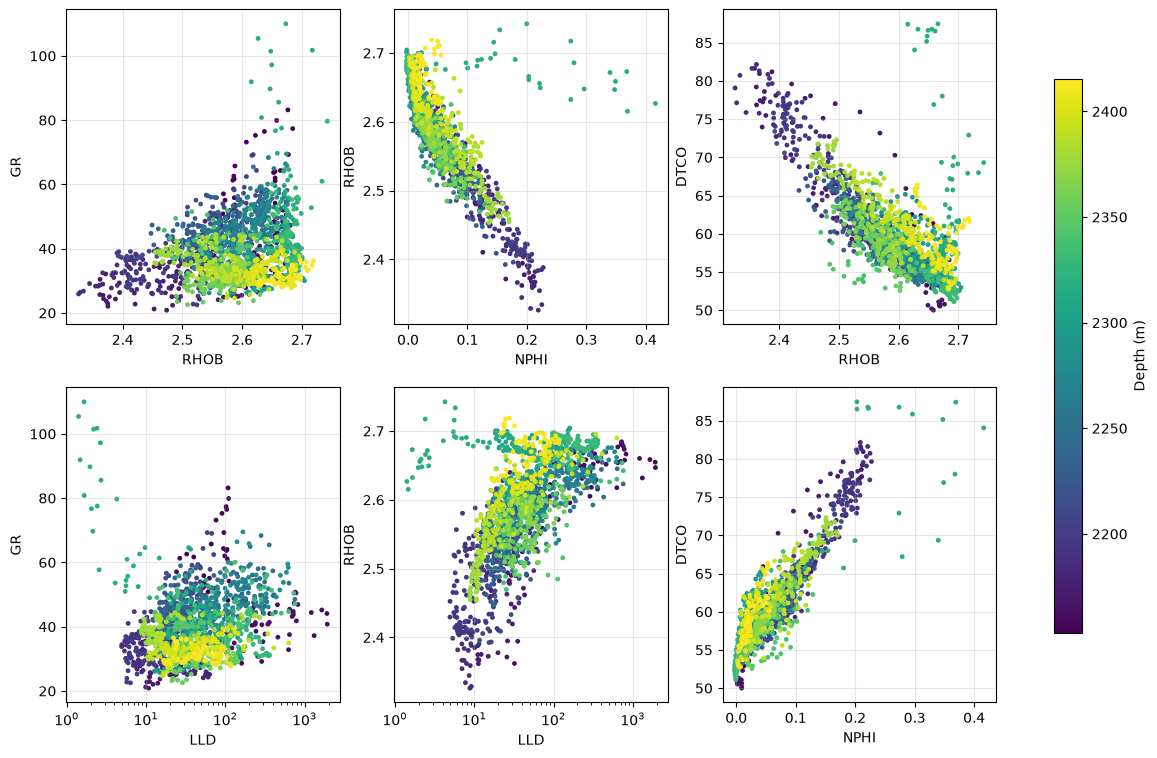

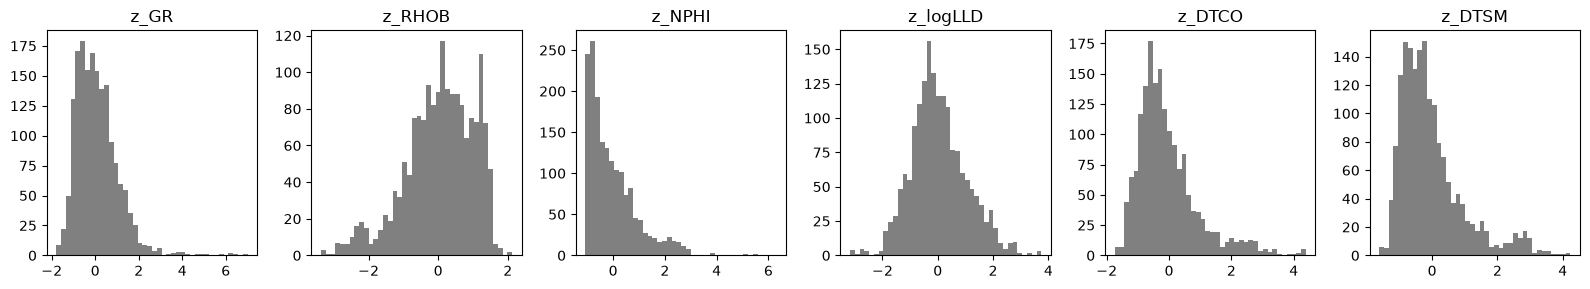

          GR  RHOB  NPHI  logLLD  DTCO  DTSM
GR      1.00  0.29 -0.05    0.16 -0.13 -0.13
RHOB    0.29  1.00 -0.77    0.60 -0.74 -0.77
NPHI   -0.05 -0.77  1.00   -0.79  0.91  0.91
logLLD  0.16  0.60 -0.79    1.00 -0.78 -0.78
DTCO   -0.13 -0.74  0.91   -0.78  1.00  0.97
DTSM   -0.13 -0.77  0.91   -0.78  0.97  1.00


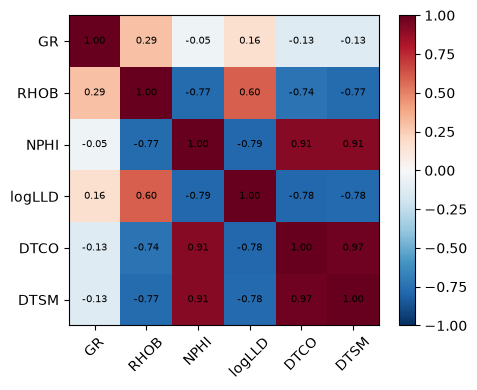


Correlation with DEPTH and HCAL (are clusters just depth trend / borehole effect?):
        vs DEPTH  vs HCAL
GR         -0.22     0.40
RHOB        0.37     0.57
NPHI       -0.25    -0.48
logLLD      0.05     0.41
DTCO       -0.19    -0.41
DTSM       -0.22    -0.43


In [16]:
good = df[~df.flag]
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
pairs = [("RHOB","GR"), ("NPHI","RHOB"), ("RHOB","DTCO"), ("LLD","GR"), ("LLD","RHOB"), ("NPHI","DTCO")]
for a, (x, y) in zip(ax.ravel(), pairs):
    sc = a.scatter(good[x], good[y], c=good["DEPTH"], s=6, cmap="viridis")   # colour = depth
    if x == "LLD": a.set_xscale("log")
    if y == "LLD": a.set_yscale("log")
    a.set_xlabel(x); a.set_ylabel(y); a.grid(alpha=0.3)
fig.colorbar(sc, ax=ax, label="Depth (m)", shrink=0.8)
plt.savefig("crossplots.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 6, figsize=(16, 3))
for a, f in zip(ax, FEATURES_B):
    a.hist(good["z_" + f], bins=40, color="gray"); a.set_title("z_" + f)
plt.tight_layout(); plt.show()

corr = good[FEATURES_B].corr()
print(corr.round(2).to_string())
plt.figure(figsize=(5, 4)); plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(6), FEATURES_B, rotation=45); plt.yticks(range(6), FEATURES_B)
for i in range(6):
    for j in range(6): plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.show()

print("\nCorrelation with DEPTH and HCAL (are clusters just depth trend / borehole effect?):")
print(pd.DataFrame({"vs DEPTH": good[FEATURES_B].corrwith(good["DEPTH"]),
                    "vs HCAL":  good[FEATURES_B].corrwith(good["HCAL"])}).round(2).to_string())

features  K       BIC       AIC  loglik_train  loglik_test  converged
   Set A  2 10527.901 10377.328        -3.882       -3.827       True
   Set A  3  9252.212  9023.756        -3.362       -3.560       True
   Set A  4  8990.126  8683.787        -3.223       -3.587       True
   Set A  5  8857.318  8473.096        -3.132       -3.530       True
   Set A  6  8729.533  8267.429        -3.043       -3.794       True
   Set B  2 10951.548 10665.978        -3.971       -3.787       True
   Set B  3  9735.058  9304.107        -3.438       -3.388       True
   Set B  4  9099.715  8523.383        -3.123       -3.781       True
   Set B  5  8631.652  7909.938        -2.871       -3.710       True
   Set B  6  8334.410  7467.316        -2.684       -3.871       True

Set A: lowest BIC at K=6, lowest AIC at K=6, highest test log-likelihood at K=5

Set B: lowest BIC at K=6, lowest AIC at K=6, highest test log-likelihood at K=3


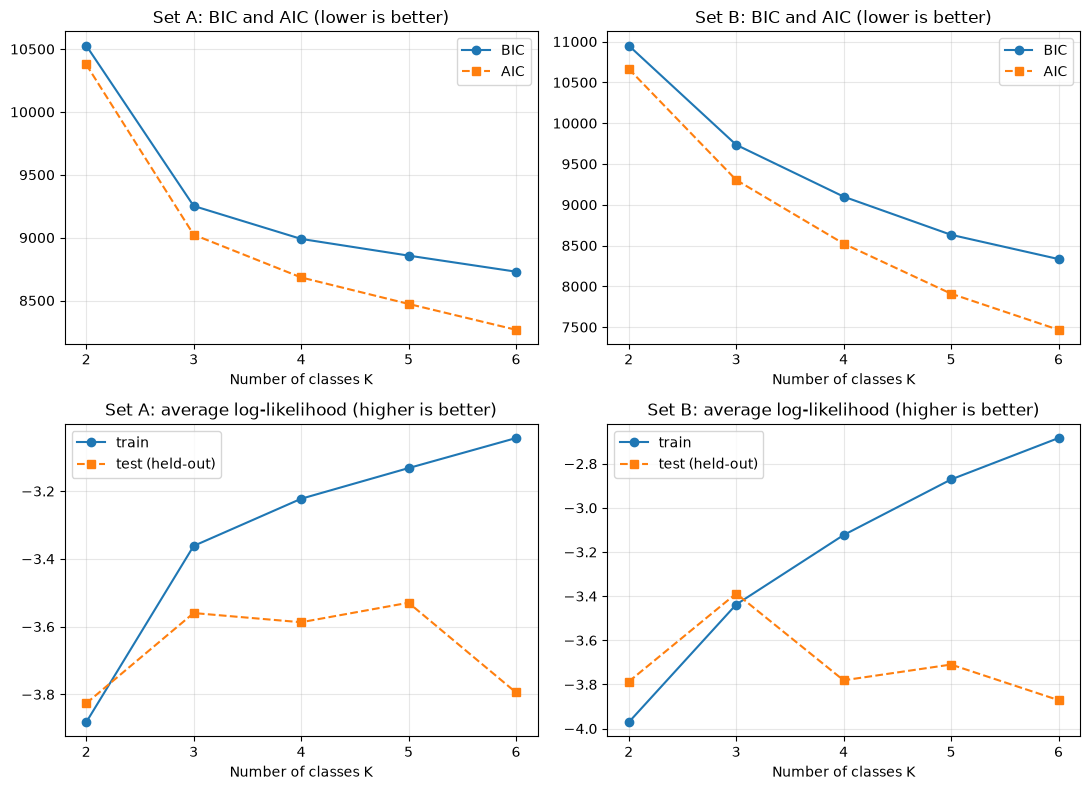

In [17]:
# ---------------- Step 3A: baseline Gaussian mixture ----------------
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

K_LIST   = [2, 3, 4, 5, 6]     # decided BEFORE looking at any result
COV_TYPE = "full"              # "full" or "diag"
N_INIT   = 10                  # random restarts per fit
SEED     = 42                  # makes the results repeatable
feature_sets = {"Set A": FEATURES_A, "Set B": FEATURES_B}

rows = []
for set_name, feats in feature_sets.items():
    cols = ["z_" + f for f in feats]
    X_train = df.loc[fit_mask, cols].values        # training samples that passed QC
    X_test  = df.loc[test_mask, cols].values       # held-out blocks that passed QC
    for k in K_LIST:
        gmm = GaussianMixture(n_components=k, covariance_type=COV_TYPE,
                              n_init=N_INIT, random_state=SEED, reg_covar=1e-6)
        gmm.fit(X_train)
        rows.append({
            "features": set_name, "K": k,
            "BIC": gmm.bic(X_train), "AIC": gmm.aic(X_train),
            "loglik_train": gmm.score(X_train),     # average log-likelihood per sample
            "loglik_test":  gmm.score(X_test),
            "converged": gmm.converged_,
        })
results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

# best K by each criterion (within each feature set; not comparable across sets)
for set_name in feature_sets:
    r = results[results["features"] == set_name].set_index("K")
    print(f"\n{set_name}: lowest BIC at K={r['BIC'].idxmin()}, lowest AIC at K={r['AIC'].idxmin()}, "
          f"highest test log-likelihood at K={r['loglik_test'].idxmax()}")

# plots: top row = BIC and AIC, bottom row = average log-likelihood (train vs test)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for j, set_name in enumerate(feature_sets):
    r = results[results["features"] == set_name]
    axes[0, j].plot(r["K"], r["BIC"], "o-", label="BIC")
    axes[0, j].plot(r["K"], r["AIC"], "s--", label="AIC")
    axes[0, j].set_title(f"{set_name}: BIC and AIC (lower is better)")
    axes[1, j].plot(r["K"], r["loglik_train"], "o-", label="train")
    axes[1, j].plot(r["K"], r["loglik_test"], "s--", label="test (held-out)")
    axes[1, j].set_title(f"{set_name}: average log-likelihood (higher is better)")
    for i in (0, 1):
        axes[i, j].set_xlabel("Number of classes K")
        axes[i, j].set_xticks(K_LIST)
        axes[i, j].grid(alpha=0.3)
        axes[i, j].legend()
plt.tight_layout()
plt.savefig("gmm_model_selection.png", dpi=150)
plt.show()

final average log-likelihood of each restart: [-3.2218 -3.2218 -3.225  -3.2218 -3.2218 -3.2218 -3.2228 -3.2218 -3.2218
 -3.2307]
best run: 44 iterations, train loglik -3.2218
log-likelihood never decreased: True

                            mine   sklearn
train avg loglik         -3.2218   -3.2218
test avg loglik          -3.5825   -3.5825
BIC (train)               8987.8    8987.8

class weights (sorted)  mine:    [0.014 0.244 0.322 0.42 ]
class weights (sorted)  sklearn: [0.014 0.244 0.322 0.419]


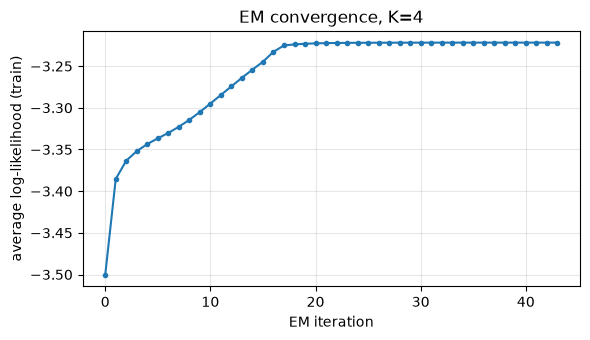

In [18]:
# ---------------- Step 3B: EM for a Gaussian mixture, from scratch ----------------
from scipy.stats import multivariate_normal
from scipy.special import logsumexp
from sklearn.cluster import KMeans

def log_gauss(X, means, covs):
    """(n, K) matrix: log N(x_i | mean_k, cov_k) for every sample and class."""
    return np.column_stack([multivariate_normal.logpdf(X, mean=means[k], cov=covs[k])
                            for k in range(len(means))])

def m_step(X, resp, reg):
    """Update weights, means and covariances from the responsibilities."""
    n, d = X.shape
    Nk = resp.sum(axis=0)                          # effective number of samples per class
    weights = Nk / n
    means = (resp.T @ X) / Nk[:, None]
    covs = np.empty((resp.shape[1], d, d))
    for k in range(resp.shape[1]):
        diff = X - means[k]
        covs[k] = (resp[:, [k]] * diff).T @ diff / Nk[k] + reg * np.eye(d)
    return weights, means, covs

def em_gmm(X, K, seed=0, max_iter=500, tol=1e-6, reg=1e-6):
    """One EM run, started from k-means. Returns parameters, responsibilities, loglik history."""
    n, d = X.shape
    labels = KMeans(n_clusters=K, n_init=1, random_state=seed).fit_predict(X)
    resp = np.zeros((n, K)); resp[np.arange(n), labels] = 1.0       # hard start
    weights, means, covs = m_step(X, resp, reg)
    history = []
    for it in range(max_iter):
        # E-step: responsibilities, computed in log space so nothing underflows
        log_prob = log_gauss(X, means, covs) + np.log(weights)
        log_norm = logsumexp(log_prob, axis=1)
        resp = np.exp(log_prob - log_norm[:, None])
        history.append(log_norm.mean())                              # average log-likelihood
        if it > 0 and history[-1] - history[-2] < tol:               # converged
            break
        # M-step
        weights, means, covs = m_step(X, resp, reg)
    return weights, means, covs, resp, np.array(history)

def avg_loglik(X, weights, means, covs):
    return logsumexp(log_gauss(X, means, covs) + np.log(weights), axis=1).mean()

# ---- run it: Feature Set A, K = 4, several restarts, keep the best ----
K = 4
cols = ["z_" + f for f in FEATURES_A]
X_train = df.loc[fit_mask, cols].values
X_test  = df.loc[test_mask, cols].values

runs = [em_gmm(X_train, K, seed=s) for s in range(10)]
best = max(runs, key=lambda r: r[4][-1])
weights, means, covs, resp, hist = best
print("final average log-likelihood of each restart:", np.round([r[4][-1] for r in runs], 4))
print(f"best run: {len(hist)} iterations, train loglik {hist[-1]:.4f}")
print("log-likelihood never decreased:", bool(np.all(np.diff(hist) > -1e-9)))

# BIC from the formula: -2 * total loglik + (number of parameters) * ln(n)
n, d = X_train.shape
n_params = K * d + K * d * (d + 1) // 2 + (K - 1)
bic = -2 * hist[-1] * n + n_params * np.log(n)

# ---- compare with scikit-learn (same tolerance, so both are fully converged) ----
sk = GaussianMixture(K, covariance_type="full", n_init=10, random_state=42,
                     reg_covar=1e-6, tol=1e-6, max_iter=500).fit(X_train)
print(f"\n{'':22s}{'mine':>10s}{'sklearn':>10s}")
print(f"{'train avg loglik':22s}{hist[-1]:10.4f}{sk.score(X_train):10.4f}")
print(f"{'test avg loglik':22s}{avg_loglik(X_test, weights, means, covs):10.4f}{sk.score(X_test):10.4f}")
print(f"{'BIC (train)':22s}{bic:10.1f}{sk.bic(X_train):10.1f}")
print("\nclass weights (sorted)  mine:   ", np.round(np.sort(weights), 3))
print("class weights (sorted)  sklearn:", np.round(np.sort(sk.weights_), 3))

plt.figure(figsize=(6, 3.5))
plt.plot(hist, "o-", markersize=3)
plt.xlabel("EM iteration"); plt.ylabel("average log-likelihood (train)")
plt.title(f"EM convergence, K={K}"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("em_convergence.png", dpi=150); plt.show()

converged: True | active classes: 5 of 5
posterior mean weights: [0.414 0.246 0.24  0.085 0.015]
avg log-likelihood  train -3.1828   test -3.5241

Posterior median and 95% credible interval of each class mean (original units):
 class               weight                   GR              RHOB                 NPHI                  LLD
     0 0.414 [0.388, 0.440] 38.82 [38.17, 39.44] 2.55 [2.54, 2.55] 0.072 [0.069, 0.074]    26.9 [25.7, 28.2]
     1 0.246 [0.224, 0.270] 45.67 [44.71, 46.65] 2.65 [2.65, 2.66] 0.011 [0.010, 0.011] 121.1 [108.5, 133.3]
     2 0.239 [0.218, 0.262] 32.08 [31.75, 32.42] 2.62 [2.61, 2.62] 0.031 [0.029, 0.033]    42.9 [40.5, 45.5]
     3 0.085 [0.071, 0.100] 33.29 [32.35, 34.30] 2.42 [2.41, 2.43] 0.177 [0.173, 0.182]      9.9 [9.1, 10.8]
     4 0.015 [0.009, 0.023] 76.66 [68.27, 85.06] 2.67 [2.65, 2.69] 0.247 [0.206, 0.291]       3.2 [2.3, 4.3]

Share of good samples by most probable class (%):
class_map
0    42.5
1    27.1
2    21.1
3     7.7
4     1.6
Samples 

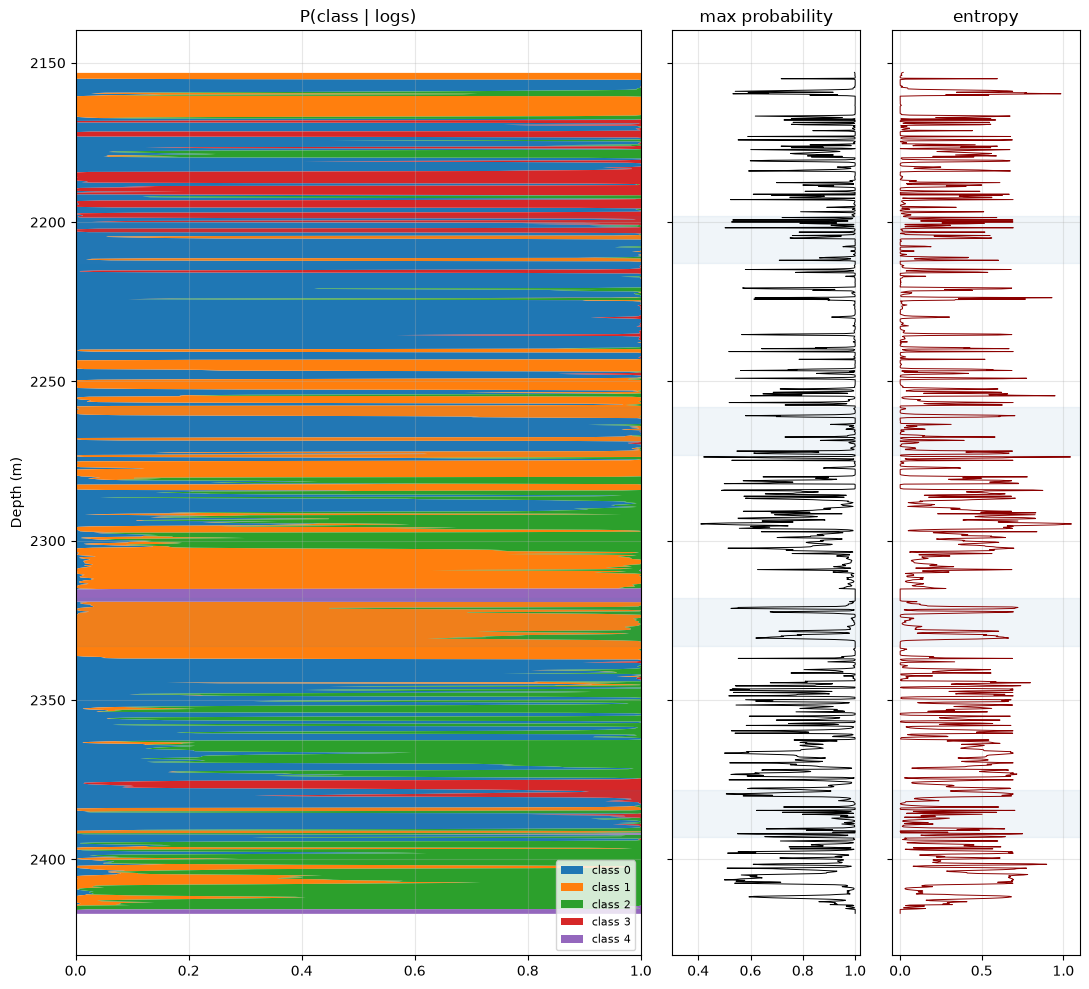

In [19]:
# ---------------- Step 4: Bayesian Gaussian mixture ----------------
from sklearn.mixture import BayesianGaussianMixture, GaussianMixture
from scipy.stats import wishart

FEATS = FEATURES_A                  # change to FEATURES_B to repeat with the sonic curves
cols = ["z_" + f for f in FEATS]
d = len(cols)
X_train = df.loc[fit_mask, cols].values
X_test  = df.loc[test_mask, cols].values
X_all   = df[cols].values

# ---- priors (the data are standardized, so "0" and "1" are meaningful) ----
K_MAX     = 5        # number of classes allowed (one of the shortlist 3, 4, 5)
ALPHA0    = 0.1      # Dirichlet prior on the class weights (<1 favours unequal weights)
BETA0     = 0.1      # strength of the prior on the class means (about 0.1 pseudo-samples)
NU0       = d + 2    # prior degrees of freedom for the covariances (weak)
COV_SCALE = 0.25     # prior guess for a class covariance: 0.25 * identity
MIN_W     = 0.005    # a class counts as "active" if its mean weight is above this
SEED      = 42

def fit_bgm(K, alpha0=ALPHA0, beta0=BETA0, cov_scale=COV_SCALE):
    return BayesianGaussianMixture(
        n_components=K, covariance_type="full",
        weight_concentration_prior_type="dirichlet_distribution",
        weight_concentration_prior=alpha0,
        mean_prior=np.zeros(d), mean_precision_prior=beta0,
        degrees_of_freedom_prior=NU0, covariance_prior=NU0 * cov_scale * np.eye(d),
        n_init=10, max_iter=2000, tol=1e-6, reg_covar=1e-6, random_state=SEED,
    ).fit(X_train)

# ---- 1. main fit ----
bgm = fit_bgm(K_MAX)
order  = np.argsort(-bgm.weights_)                       # biggest class first
active = [k for k in order if bgm.weights_[k] > MIN_W]
print(f"converged: {bgm.converged_} | active classes: {len(active)} of {K_MAX}")
print("posterior mean weights:", np.round(bgm.weights_[order], 3))
print(f"avg log-likelihood  train {bgm.score(X_train):.4f}   test {bgm.score(X_test):.4f}")

# ---- 2. posterior samples -> 95 % credible intervals ----
rng = np.random.default_rng(SEED)
S = 2000
w_samples = rng.dirichlet(bgm.weight_concentration_, size=S)       # (S, K_MAX)

def sample_means(k):
    """Draw S samples of the mean of class k from its Normal-Wishart posterior."""
    nu, beta, m = bgm.degrees_of_freedom_[k], bgm.mean_precision_[k], bgm.means_[k]
    W = np.linalg.inv(bgm.covariances_[k] * nu)                    # Wishart scale matrix
    Lam = wishart.rvs(df=nu, scale=W, size=S, random_state=rng)    # precision matrices
    chol = np.linalg.cholesky(np.linalg.inv(Lam) / beta)
    return m + np.einsum("sij,sj->si", chol, rng.standard_normal((S, d)))

def fmt(x, nd=2):
    lo, med, hi = np.percentile(x, [2.5, 50, 97.5])
    return f"{med:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

rows = []
for rank, k in enumerate(active):
    z = sample_means(k) * sd[FEATS].values + mu[FEATS].values      # back to original units
    row = {"class": rank, "weight": fmt(w_samples[:, k], 3)}
    for j, f in enumerate(FEATS):
        if f == "logLLD":
            row["LLD"] = fmt(10 ** z[:, j], 1)                     # log10 -> ohm.m
        else:
            row[f] = fmt(z[:, j], 3 if f == "NPHI" else 2)
    rows.append(row)
print("\nPosterior median and 95% credible interval of each class mean (original units):")
print(pd.DataFrame(rows).to_string(index=False))

# ---- 3. class probabilities P(class | logs) for every depth ----
proba = bgm.predict_proba(X_all)[:, active]
proba = proba / proba.sum(axis=1, keepdims=True)
for rank in range(len(active)):
    df[f"p_class{rank}"] = proba[:, rank]
df["class_map"] = proba.argmax(axis=1)
df["p_max"] = proba.max(axis=1)
df["entropy"] = -(proba * np.log(proba + 1e-12)).sum(axis=1)
print("\nShare of good samples by most probable class (%):")
print((100 * df.loc[~df.flag, "class_map"].value_counts(normalize=True).sort_index()).round(1).to_string())
print(f"Samples with p_max < 0.7 (uncertain): {(df.p_max < 0.7).mean() * 100:.1f} %")

# ---- 4. shortlist: Bayesian vs plain GMM for K = 3, 4, 5, 6 ----
print("\nAverage log-likelihood, Bayesian mixture vs plain GMM:")
print(f"{'K':>3s}{'BGM train':>11s}{'BGM test':>10s}{'GMM train':>11s}{'GMM test':>10s}")
for K in [3, 4, 5, 6]:
    b = fit_bgm(K)
    g = GaussianMixture(K, covariance_type="full", n_init=10, random_state=SEED,
                        reg_covar=1e-6, tol=1e-6, max_iter=500).fit(X_train)
    print(f"{K:3d}{b.score(X_train):11.3f}{b.score(X_test):10.3f}{g.score(X_train):11.3f}{g.score(X_test):10.3f}")

# ---- 5. prior sensitivity (at K_MAX): change one prior at a time ----
print(f"\nPrior sensitivity at K={K_MAX} (test avg log-likelihood; class weights sorted):")
settings = [("baseline", {})]
settings += [(f"alpha0={a}", {"alpha0": a}) for a in [0.01, 1.0, 10.0, 100.0]]
settings += [(f"beta0={b}", {"beta0": b}) for b in [0.01, 1.0, 10.0]]
settings += [(f"cov_scale={c}", {"cov_scale": c}) for c in [0.05, 1.0]]
for name, kw in settings:
    m = fit_bgm(K_MAX, **kw)
    print(f"  {name:14s} test {m.score(X_test):7.3f}   weights {np.round(np.sort(m.weights_)[::-1], 3)}")

# ---- 6. plot: class probabilities and uncertainty versus depth ----
fig, ax = plt.subplots(1, 3, figsize=(11, 10), sharey=True, gridspec_kw={"width_ratios": [3, 1, 1]})
cum = np.zeros(len(df))
colors = plt.cm.tab10(np.arange(len(active)))
for rank in range(len(active)):
    ax[0].fill_betweenx(df.DEPTH, cum, cum + proba[:, rank], color=colors[rank],
                        label=f"class {rank}", linewidth=0)
    cum += proba[:, rank]
ax[0].set_xlim(0, 1); ax[0].set_title("P(class | logs)"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].plot(df.p_max, df.DEPTH, color="black", linewidth=0.7)
ax[1].set_xlim(0.3, 1.02); ax[1].set_title("max probability")
ax[2].plot(df.entropy, df.DEPTH, color="darkred", linewidth=0.7); ax[2].set_title("entropy")
for a in ax:
    a.grid(alpha=0.3)
    for b in df.loc[df.set == "test", "block"].unique():          # shade held-out blocks
        t = df[df.block == b].DEPTH
        a.axhspan(t.min(), t.max(), color="steelblue", alpha=0.08)
ax[0].set_ylabel("Depth (m)"); ax[0].invert_yaxis()
plt.tight_layout(); plt.savefig("bayes_class_probabilities.png", dpi=150); plt.show()

train segments: [296, 295, 295, 295, 148]
test segments : [98, 99, 99, 98]
self-test (should match): -2.579153 -2.579153

Average log-likelihood per sample:
                        train     test
GMM (no continuity)    -3.131   -3.502
HMM  (MLE)             -2.120   -2.543
HMM  (Bayesian)        -2.132   -2.431
EM iterations: MLE 69  Bayesian 30 | log-lik never decreased: True

Expected number of transitions (rows = from, columns = to):
       c0     c1     c2     c3    c4
c0  407.2   13.2    5.0    9.6   0.0
c1   12.0  359.7    8.3    1.1   0.0
c2    7.1    7.3  302.5    0.0   1.0
c3    7.3    1.5    0.0  161.4   0.0
c4    0.0    0.0    0.0    0.0  19.7

Bayesian transition probabilities: median [2.5%, 97.5%]
                         c0                       c1                       c2                       c3                       c4
c0  0.9283 [0.9014, 0.9496]  0.0313 [0.0177, 0.0502]  0.0131 [0.0050, 0.0262]  0.0235 [0.0121, 0.0411]  0.0016 [0.0001, 0.0087]
c1  0.0329 [0.0179, 0.05

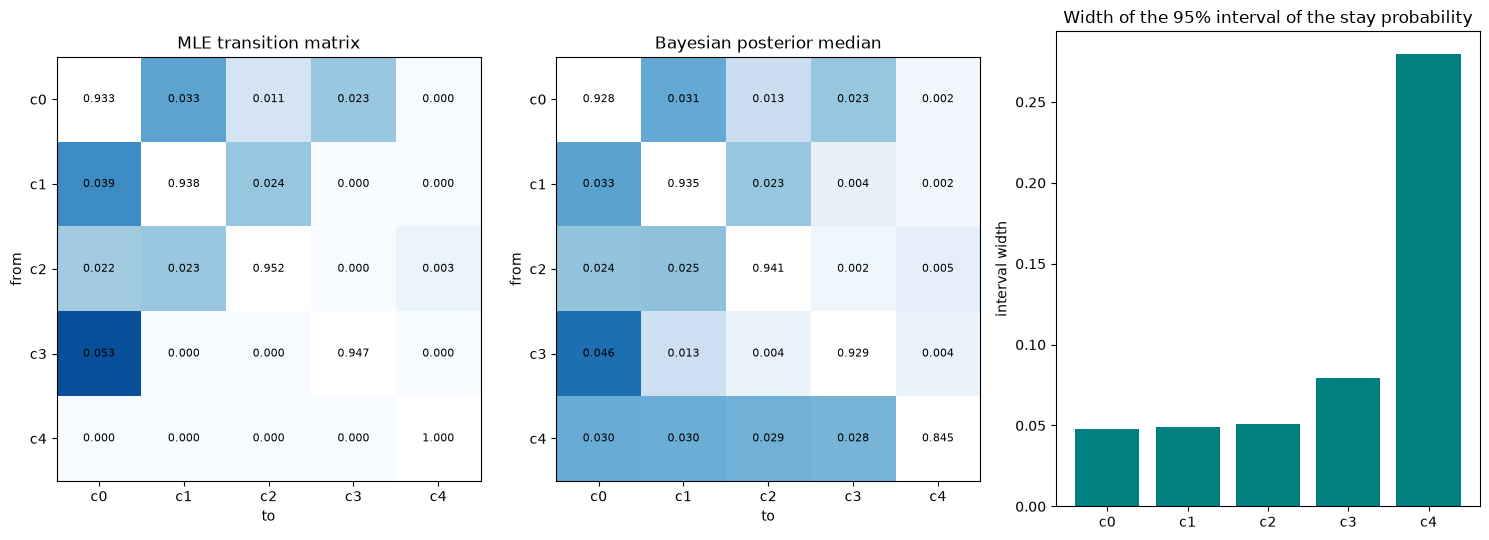

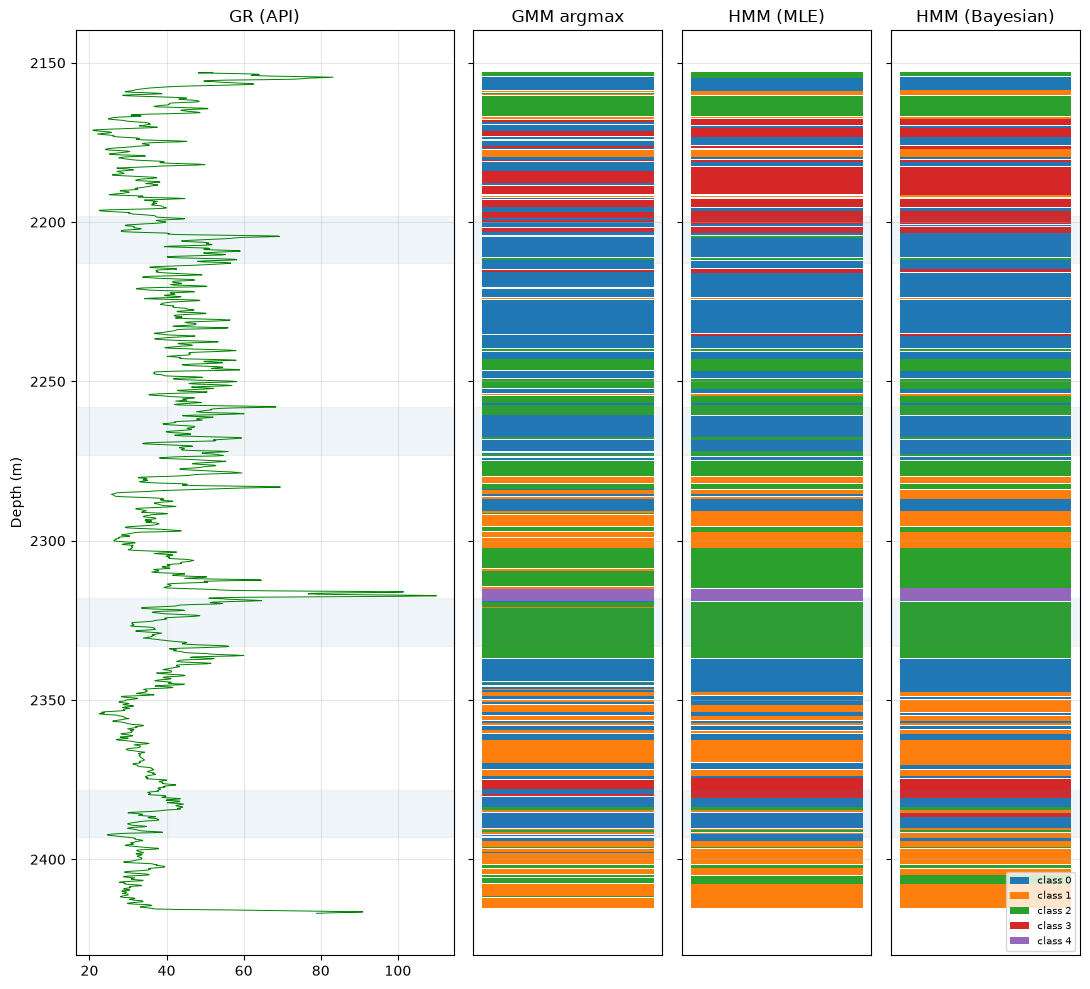

In [20]:
# ---------------- Step 5: Hidden Markov Model (MLE and Bayesian) ----------------
import itertools
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
from sklearn.mixture import GaussianMixture

FEATS   = FEATURES_A
cols    = ["z_" + f for f in FEATS]
K       = 5                      # number of classes (hidden states)
REG     = 1e-6                   # keeps covariances invertible
SEED    = 42

# ---- 0. split the data into contiguous SEGMENTS (never join rows across a gap) ----
def segments(mask):
    """List of row-index arrays, one per run of consecutive True rows."""
    idx = np.where(mask.values)[0]
    breaks = np.where(np.diff(idx) > 1)[0] + 1
    return np.split(idx, breaks)

train_segs = segments(fit_mask)
test_segs  = segments(test_mask)
all_segs   = segments(~df.flag)                       # whole well, flagged tail removed
Z = df[cols].values
print(f"train segments: {[len(s) for s in train_segs]}")
print(f"test segments : {[len(s) for s in test_segs]}")

# ---- 1. forward-backward in log space ----
def log_emission(X, means, covs):
    return np.column_stack([multivariate_normal.logpdf(X, mean=means[k], cov=covs[k])
                            for k in range(len(means))])

def forward_backward(logB, logA, logpi):
    T, Kk = logB.shape
    la = np.empty((T, Kk)); lb = np.zeros((T, Kk))
    la[0] = logpi + logB[0]
    for t in range(1, T):
        la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
    for t in range(T - 2, -1, -1):
        lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
    loglik = logsumexp(la[-1])
    gamma = np.exp(la + lb - loglik)                                   # P(state_t | all data)
    xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - loglik).sum(axis=0)
    return loglik, gamma, xi                                           # xi = expected transition counts

def viterbi(logB, logA, logpi):
    T, Kk = logB.shape
    delta = np.empty((T, Kk)); back = np.zeros((T, Kk), int)
    delta[0] = logpi + logB[0]
    for t in range(1, T):
        s = delta[t - 1][:, None] + logA
        back[t] = s.argmax(axis=0); delta[t] = s.max(axis=0) + logB[t]
    path = np.empty(T, int); path[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):
        path[t] = back[t + 1, path[t + 1]]
    return path

# quick self-test on a tiny HMM: forward algorithm vs brute-force enumeration
rs = np.random.default_rng(0)
Ak = rs.dirichlet(np.ones(2), 2); pik = np.array([0.6, 0.4]); Bk = rs.random((5, 2))
brute = sum(pik[p[0]] * Bk[0, p[0]] * np.prod([Ak[p[t-1], p[t]] * Bk[t, p[t]] for t in range(1, 5)])
            for p in itertools.product(range(2), repeat=5))
print("self-test (should match):", round(forward_backward(np.log(Bk), np.log(Ak), np.log(pik))[0], 6),
      round(np.log(brute), 6))

# ---- 2. Baum-Welch (EM) with an optional Dirichlet prior on the transitions ----
def fit_hmm(prior=None, n_iter=300, tol=1e-6):
    """prior=None -> maximum likelihood. prior=(K,K) Dirichlet pseudo-counts -> Bayesian."""
    gmm = GaussianMixture(K, covariance_type="full", n_init=10, random_state=SEED,
                          reg_covar=REG, tol=1e-6, max_iter=500).fit(np.vstack([Z[s] for s in train_segs]))
    means, covs = gmm.means_.copy(), gmm.covariances_.copy()
    A = np.full((K, K), 0.1 / (K - 1)); np.fill_diagonal(A, 0.9)       # sticky starting guess
    pi = gmm.weights_.copy()
    hist = []
    for it in range(n_iter):
        Gs, xi_sum, ll = [], np.zeros((K, K)), 0.0
        for s in train_segs:                                           # E-step
            l, g, xi = forward_backward(log_emission(Z[s], means, covs), np.log(A), np.log(pi))
            Gs.append(g); xi_sum += xi; ll += l
        hist.append(ll / sum(len(s) for s in train_segs))
        if it > 0 and hist[-1] - hist[-2] < tol:
            break
        counts = xi_sum + (prior if prior is not None else 0.0) + 1e-12   # M-step
        A = counts / counts.sum(axis=1, keepdims=True)
        Xcat = np.vstack([Z[s] for s in train_segs]); G = np.vstack(Gs)
        Nk = G.sum(axis=0); pi = Nk / Nk.sum()
        means = (G.T @ Xcat) / Nk[:, None]
        for k in range(K):
            diff = Xcat - means[k]
            covs[k] = (G[:, [k]] * diff).T @ diff / Nk[k] + REG * np.eye(len(cols))
    return dict(A=A, pi=pi, means=means, covs=covs, counts=xi_sum, hist=np.array(hist), gmm=gmm)

def avg_loglik(model, segs):
    ll = sum(forward_backward(log_emission(Z[s], model["means"], model["covs"]),
                              np.log(model["A"]), np.log(model["pi"]))[0] for s in segs)
    return ll / sum(len(s) for s in segs)

def decode(model):
    """Viterbi path and smoothed probabilities for every good sample of the whole well."""
    path = np.full(len(df), -1); prob = np.full((len(df), K), np.nan)
    for s in all_segs:
        logB = log_emission(Z[s], model["means"], model["covs"])
        path[s] = viterbi(logB, np.log(model["A"]), np.log(model["pi"]))
        prob[s] = forward_backward(logB, np.log(model["A"]), np.log(model["pi"]))[1]
    return path, prob

def run_lengths(path):
    p = path[path >= 0]
    change = np.where(np.diff(p) != 0)[0] + 1
    return np.diff(np.r_[0, change, len(p)]), p[np.r_[0, change]]

# ---- 3. fit: maximum likelihood, and Bayesian (flat Dirichlet(1) prior on every transition) ----
mle = fit_hmm(prior=None)
bay = fit_hmm(prior=np.ones((K, K)))
gmm_train = mle["gmm"].score(np.vstack([Z[s] for s in train_segs]))
gmm_test  = mle["gmm"].score(np.vstack([Z[s] for s in test_segs]))

print("\nAverage log-likelihood per sample:")
print(f"{'':20s}{'train':>9s}{'test':>9s}")
print(f"{'GMM (no continuity)':20s}{gmm_train:9.3f}{gmm_test:9.3f}")
print(f"{'HMM  (MLE)':20s}{avg_loglik(mle, train_segs):9.3f}{avg_loglik(mle, test_segs):9.3f}")
print(f"{'HMM  (Bayesian)':20s}{avg_loglik(bay, train_segs):9.3f}{avg_loglik(bay, test_segs):9.3f}")
print("EM iterations: MLE", len(mle["hist"]), " Bayesian", len(bay["hist"]),
      "| log-lik never decreased:", bool(np.all(np.diff(mle['hist']) > -1e-9)))

# ---- 4. transition matrix and 95 % credible intervals (Bayesian) ----
order = np.argsort(-bay["pi"]); names = [f"c{r}" for r in range(K)]
A_mle = mle["A"][np.ix_(order, order)]
rng = np.random.default_rng(SEED)
post = bay["counts"][np.ix_(order, order)] + 1.0                       # posterior Dirichlet parameters
draws = np.stack([rng.dirichlet(post[i], size=4000) for i in range(K)], axis=1)   # (S, K, K)
lo, med, hi = np.percentile(draws, [2.5, 50, 97.5], axis=0)
print("\nExpected number of transitions (rows = from, columns = to):")
print(pd.DataFrame(np.round(bay["counts"][np.ix_(order, order)], 1), index=names, columns=names).to_string())
print("\nBayesian transition probabilities: median [2.5%, 97.5%]")
print(pd.DataFrame([[f"{med[i,j]:.4f} [{lo[i,j]:.4f}, {hi[i,j]:.4f}]" for j in range(K)]
                    for i in range(K)], index=names, columns=names).to_string())
print("\nMLE transition matrix:"); print(pd.DataFrame(A_mle, index=names, columns=names).round(4).to_string())
print("\nMean dwell length (samples) = 1/(1 - p_stay):", np.round(1 / (1 - np.diag(med)), 1))

# ---- 5. does the HMM over-smooth? compare run lengths and thin-bed survival ----
gmm_path = np.full(len(df), -1)
for s in all_segs:
    gmm_path[s] = mle["gmm"].predict(Z[s])
path_mle, prob_mle = decode(mle)
path_bay, prob_bay = decode(bay)
thin = np.zeros(len(df), bool); thin[(df.DEPTH >= 2315) & (df.DEPTH < 2319)] = True; thin &= ~df.flag.values
print("\nNumber of class runs over the whole well, and runs shorter than 10 samples:")
for name, p in [("GMM argmax", gmm_path), ("HMM MLE", path_mle), ("HMM Bayesian", path_bay)]:
    rl, _ = run_lengths(p)
    top_class = np.bincount(p[thin]).argmax()
    print(f"  {name:13s} runs={len(rl):4d}  runs<10={int((rl < 10).sum()):4d}  "
          f"thin-bed samples in one class: {100 * np.mean(p[thin] == top_class):.0f} %")

# ---- 6. sensitivity to the transition prior: add extra "stay" pseudo-counts on the diagonal ----
print("\nSensitivity to the transition prior (flat prior + extra stay pseudo-counts):")
print(f"{'extra stay':>11s}{'train':>8s}{'test':>8s}{'runs':>6s}{'runs<10':>9s}{'thin bed %':>12s}{'min dwell':>11s}")
for extra in [0, 10, 100, 1000]:
    m = fit_hmm(prior=np.ones((K, K)) + extra * np.eye(K))
    p, _ = decode(m)
    rl, _ = run_lengths(p)
    top = np.bincount(p[thin]).argmax()
    dwell = 1 / (1 - np.diag(m["A"]))
    print(f"{extra:11d}{avg_loglik(m, train_segs):8.3f}{avg_loglik(m, test_segs):8.3f}{len(rl):6d}"
          f"{int((rl < 10).sum()):9d}{100 * np.mean(p[thin] == top):12.0f}{dwell.min():11.1f}")

# ---- 7. plots ----
fig, ax = plt.subplots(1, 3, figsize=(15, 5.5))
for a, M, title in [(ax[0], A_mle, "MLE transition matrix"), (ax[1], med, "Bayesian posterior median")]:
    off = M.copy(); np.fill_diagonal(off, np.nan)                     # colour only the off-diagonal terms
    a.imshow(off, cmap="Blues", vmin=0, vmax=0.06)
    for i in range(K):
        for j in range(K):
            a.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=8,
                   color="black")
    a.set_xticks(range(K)); a.set_xticklabels(names); a.set_yticks(range(K)); a.set_yticklabels(names)
    a.set_xlabel("to"); a.set_ylabel("from"); a.set_title(title)
ax[2].bar(names, (hi - lo)[np.arange(K), np.arange(K)], color="teal")
ax[2].set_title("Width of the 95% interval of the stay probability"); ax[2].set_ylabel("interval width")
plt.tight_layout(); plt.savefig("hmm_transition_matrix.png", dpi=150); plt.show()

# class sequences versus depth: GMM argmax, HMM MLE, HMM Bayesian
fmap = {int(k): r for r, k in enumerate(order)}                       # relabel states by class size
def relabel(path):
    out = np.full(len(path), -1)
    for k, r in fmap.items(): out[path == k] = r
    return out
gmm_rank = np.argsort(-mle["gmm"].weights_); g_map = {int(k): r for r, k in enumerate(gmm_rank)}
gmm_lab = np.full(len(df), -1)
for k, r in g_map.items(): gmm_lab[gmm_path == k] = r
panels = [("GR", None), ("GMM argmax", gmm_lab), ("HMM (MLE)", relabel(path_mle)), ("HMM (Bayesian)", relabel(path_bay))]
fig, axs = plt.subplots(1, 4, figsize=(11, 10), sharey=True, gridspec_kw={"width_ratios": [2, 1, 1, 1]})
colors = plt.cm.tab10(np.arange(K))
axs[0].plot(df.GR, df.DEPTH, color="green", linewidth=0.7); axs[0].set_title("GR (API)")
for a, (title, lab) in zip(axs[1:], panels[1:]):
    for r in range(K):
        a.fill_betweenx(df.DEPTH, 0, 1, where=(lab == r), color=colors[r], step="mid", linewidth=0,
                        label=f"class {r}" if title == "HMM (Bayesian)" else None)
    a.set_xticks([]); a.set_title(title)
axs[3].legend(fontsize=7, loc="lower right")
for a in axs:
    a.grid(alpha=0.3)
    for b in df.loc[df.set == "test", "block"].unique():
        tb = df[df.block == b].DEPTH; a.axhspan(tb.min(), tb.max(), color="steelblue", alpha=0.08)
axs[0].set_ylabel("Depth (m)"); axs[0].invert_yaxis()
plt.tight_layout(); plt.savefig("hmm_class_sequences.png", dpi=150); plt.show()

 K  GMM_test  BGM_test  HMM_train  HMM_test  runs  runs_lt10
 2    -3.827    -3.879     -3.492    -3.339    50         16
 3    -3.560    -3.583     -2.782    -2.992    59         26
 4    -3.587    -3.587     -2.357    -2.642    59         18
 5    -3.530    -3.524     -2.132    -2.431    89         39
 6    -3.794    -3.744     -1.825    -2.759   105         52


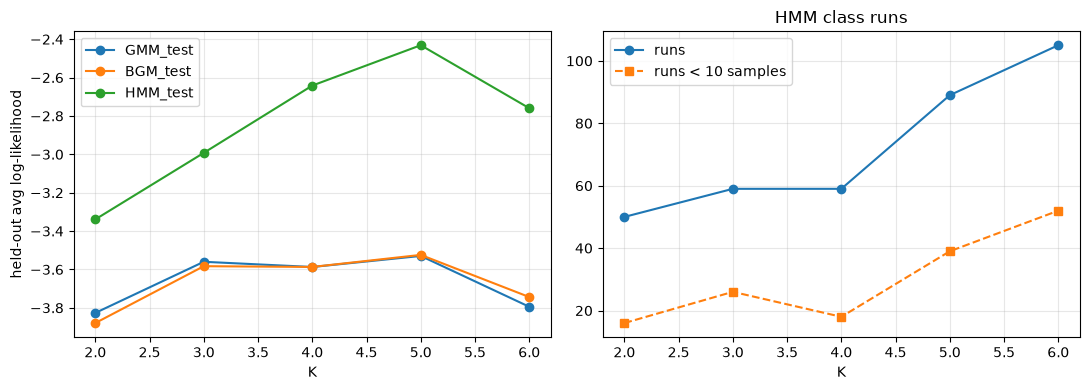


Posterior predictive check (mixture), held-out blocks:
                  observed  rep median  rep 2.5%  rep 97.5%    ppp
mean GR              0.342      -0.003    -0.100      0.103  0.000
mean RHOB            0.182      -0.002    -0.102      0.091  0.000
mean NPHI           -0.113       0.001    -0.100      0.097  0.986
mean logLLD          0.173       0.001    -0.092      0.094  0.000
std GR               0.848       0.976     0.857      1.136  0.982
std RHOB             0.893       0.997     0.926      1.072  0.994
std NPHI             0.846       0.986     0.873      1.119  0.993
std logLLD           1.001       0.992     0.917      1.078  0.422
corr GR-RHOB         0.216       0.299     0.212      0.372  0.969
corr RHOB-NPHI      -0.842      -0.761    -0.879     -0.619  0.890
corr NPHI-logLLD    -0.893      -0.761    -0.795     -0.722  1.000
corr GR-logLLD       0.188       0.158    -0.031      0.338  0.372

Lag-1 autocorrelation on held-out blocks:
        observed  HMM median  

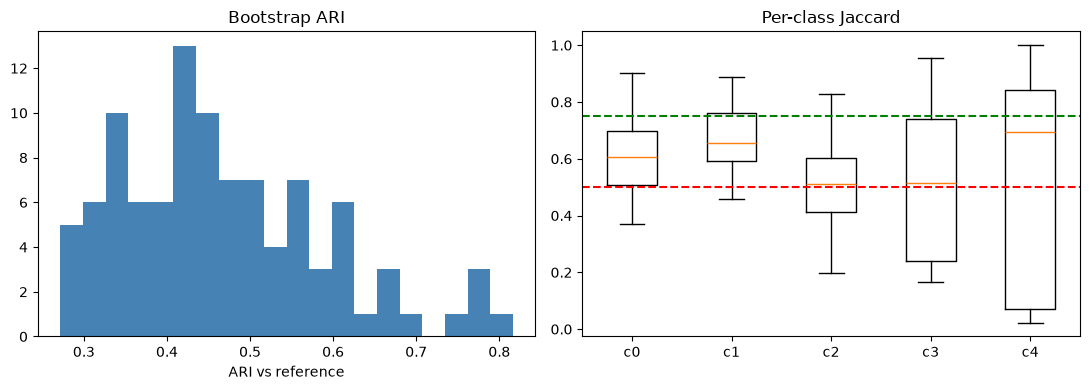

In [21]:
from sklearn.metrics import adjusted_rand_score
import warnings; warnings.filterwarnings("ignore")
rng = np.random.default_rng(42)
colsA = ["z_" + f for f in FEATURES_A]

# ---------- 6A. Held-out log-likelihood vs class count: GMM, Bayesian GMM, HMM ----------
d = len(colsA)            # fit_bgm reads global d
cols = colsA              # fit_hmm / decode read global cols
Xtr, Xte = df.loc[fit_mask, colsA].values, df.loc[test_mask, colsA].values
rows = []
for k in [2, 3, 4, 5, 6]:
    g = GaussianMixture(k, covariance_type="full", n_init=10, random_state=42, reg_covar=1e-6).fit(Xtr)
    b = fit_bgm(k)
    K = k                                   # fit_hmm / decode read global K
    h = fit_hmm(prior=np.ones((k, k)))
    path, _ = decode(h); rl, _ = run_lengths(path)
    rows.append(dict(K=k, GMM_test=g.score(Xte), BGM_test=b.score(Xte),
                     HMM_train=avg_loglik(h, train_segs), HMM_test=avg_loglik(h, test_segs),
                     runs=len(rl), runs_lt10=int((rl < 10).sum())))
val = pd.DataFrame(rows); print(val.round(3).to_string(index=False))
K = 5                                       # restore main choice

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c in ["GMM_test", "BGM_test", "HMM_test"]: ax[0].plot(val.K, val[c], "o-", label=c)
ax[0].set_xlabel("K"); ax[0].set_ylabel("held-out avg log-likelihood"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(val.K, val.runs, "o-", label="runs"); ax[1].plot(val.K, val.runs_lt10, "s--", label="runs < 10 samples")
ax[1].set_xlabel("K"); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title("HMM class runs")
plt.tight_layout(); plt.savefig("val_K_sensitivity.png", dpi=150); plt.show()

# ---------- 6B. Posterior predictive checks (replicated vs held-out data) ----------
# (i) mixture: moments and correlations
bgm5 = fit_bgm(5)
bgm5.random_state = np.random.RandomState(0)   # otherwise sklearn re-seeds .sample() and every replicate is identical
def stats(X):
    c = np.corrcoef(X.T)
    return np.r_[X.mean(0), X.std(0), c[0,1], c[1,2], c[2,3], c[0,3]]
names = [f"mean {f}" for f in FEATURES_A] + [f"std {f}" for f in FEATURES_A] + \
        ["corr GR-RHOB", "corr RHOB-NPHI", "corr NPHI-logLLD", "corr GR-logLLD"]
obs = stats(Xte)
rep = np.array([stats(bgm5.sample(len(Xte))[0]) for _ in range(1000)])
ppp = (rep >= obs).mean(0)        # extreme if < 0.025 or > 0.975
print("\nPosterior predictive check (mixture), held-out blocks:")
print(pd.DataFrame({"observed": obs, "rep median": np.median(rep, 0), "rep 2.5%": np.percentile(rep, 2.5, 0),
                    "rep 97.5%": np.percentile(rep, 97.5, 0), "ppp": ppp}, index=names).round(3).to_string())

# (ii) vertical continuity: lag-1 autocorrelation, HMM vs mixture vs observed
def lag1(X): return np.array([np.corrcoef(X[:-1, j], X[1:, j])[0, 1] for j in range(X.shape[1])])
def sim_hmm(model, T):
    A, pi, mu_, cv = model["A"], model["pi"], model["means"], model["covs"]
    s = rng.choice(len(pi), p=pi); out = np.empty((T, mu_.shape[1]))
    for t in range(T):
        out[t] = rng.multivariate_normal(mu_[s], cv[s]); s = rng.choice(len(pi), p=A[s])
    return out
hb = fit_hmm(prior=np.ones((K, K)))
obs_l = np.mean([lag1(Z[s]) for s in test_segs], 0)
rep_l = np.array([np.mean([lag1(sim_hmm(hb, len(s))) for s in test_segs], 0) for _ in range(300)])
rep_g = np.array([np.mean([lag1(bgm5.sample(len(s))[0]) for s in test_segs], 0) for _ in range(300)])
print("\nLag-1 autocorrelation on held-out blocks:")
print(pd.DataFrame({"observed": obs_l, "HMM median": np.median(rep_l, 0), "HMM 2.5%": np.percentile(rep_l, 2.5, 0),
                    "HMM 97.5%": np.percentile(rep_l, 97.5, 0), "mixture median": np.median(rep_g, 0)},
                   index=FEATURES_A).round(3).to_string())

# ---------- 6C. Cluster stability: block bootstrap of the training blocks ----------
REF_K = 5
ref = GaussianMixture(REF_K, covariance_type="full", n_init=10, random_state=42, reg_covar=1e-6).fit(Xtr)
good_df = df.loc[~df.flag]; Xgood = good_df[colsA].values
ref_lab = ref.predict(Xgood)
train_blocks = df.loc[fit_mask, "block"].unique()
def jaccard_per_class(a, b, ka, kb):
    return np.array([max(np.sum((a == i) & (b == j)) / np.sum((a == i) | (b == j)) for j in range(kb)) for i in range(ka)])
N_BOOT = 100
ari, jac = [], []
for r in range(N_BOOT):
    pick = rng.choice(train_blocks, len(train_blocks), replace=True)      # resample whole 15 m blocks
    Xb = np.vstack([df.loc[(df.block == b) & fit_mask, colsA].values for b in pick])
    gb = GaussianMixture(REF_K, covariance_type="full", n_init=3, random_state=int(rng.integers(1e6)), reg_covar=1e-6).fit(Xb)
    lab = gb.predict(Xgood)
    ari.append(adjusted_rand_score(ref_lab, lab)); jac.append(jaccard_per_class(ref_lab, lab, REF_K, REF_K))
jac = np.array(jac)
print(f"\nBlock-bootstrap (K={REF_K}, {N_BOOT} resamples): ARI mean {np.mean(ari):.2f}, 5-95% [{np.percentile(ari,5):.2f}, {np.percentile(ari,95):.2f}]")
print(pd.DataFrame({"ref class": range(REF_K), "share": (np.bincount(ref_lab)/len(ref_lab)).round(3),
                    "mean Jaccard": jac.mean(0).round(2), "5th pct": np.percentile(jac, 5, 0).round(2)}).to_string(index=False))
print("Jaccard rule of thumb: >0.75 stable, 0.6-0.75 doubtful, <0.5 dissolved")

# ---------- 6D. Sensitivity to feature set and class count ----------
variants = {"Set A (reference)": FEATURES_A, "Set B (+DTCO, DTSM)": FEATURES_B,
            "A without GR": ["RHOB","NPHI","logLLD"], "A without logLLD": ["GR","RHOB","NPHI"],
            "A without NPHI": ["GR","RHOB","logLLD"], "A + DTCO": FEATURES_A + ["DTCO"]}
rows = []
for name, feats in variants.items():
    cc = ["z_" + f for f in feats]
    g = GaussianMixture(REF_K, covariance_type="full", n_init=10, random_state=42, reg_covar=1e-6).fit(df.loc[fit_mask, cc].values)
    rows.append({"features": name, "ARI vs reference": adjusted_rand_score(ref_lab, g.predict(good_df[cc].values)),
                 "test loglik (NOT comparable across rows: different dimensions)": g.score(df.loc[test_mask, cc].values)})
print("\nSensitivity to feature set (K=5):"); print(pd.DataFrame(rows).round(3).to_string(index=False))
for k in [4, 6]:
    gk = GaussianMixture(k, covariance_type="full", n_init=10, random_state=42, reg_covar=1e-6).fit(Xtr)
    print(f"ARI K=5 vs K={k}: {adjusted_rand_score(ref_lab, gk.predict(Xgood)):.2f}")
K = 5
p_hmm, _ = decode(hb)
print(f"ARI GMM(K=5) vs HMM(K=5): {adjusted_rand_score(ref_lab, p_hmm[~df.flag.values]):.2f}")

# ---------- 6E. Stability plot ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(ari, bins=20, color="steelblue"); ax[0].set_xlabel("ARI vs reference"); ax[0].set_title("Bootstrap ARI")
ax[1].boxplot(jac); ax[1].set_xticklabels([f"c{i}" for i in range(REF_K)])
ax[1].axhline(0.75, ls="--", c="g"); ax[1].axhline(0.5, ls="--", c="r"); ax[1].set_title("Per-class Jaccard")
plt.tight_layout(); plt.savefig("cluster_stability.png", dpi=150); plt.show()

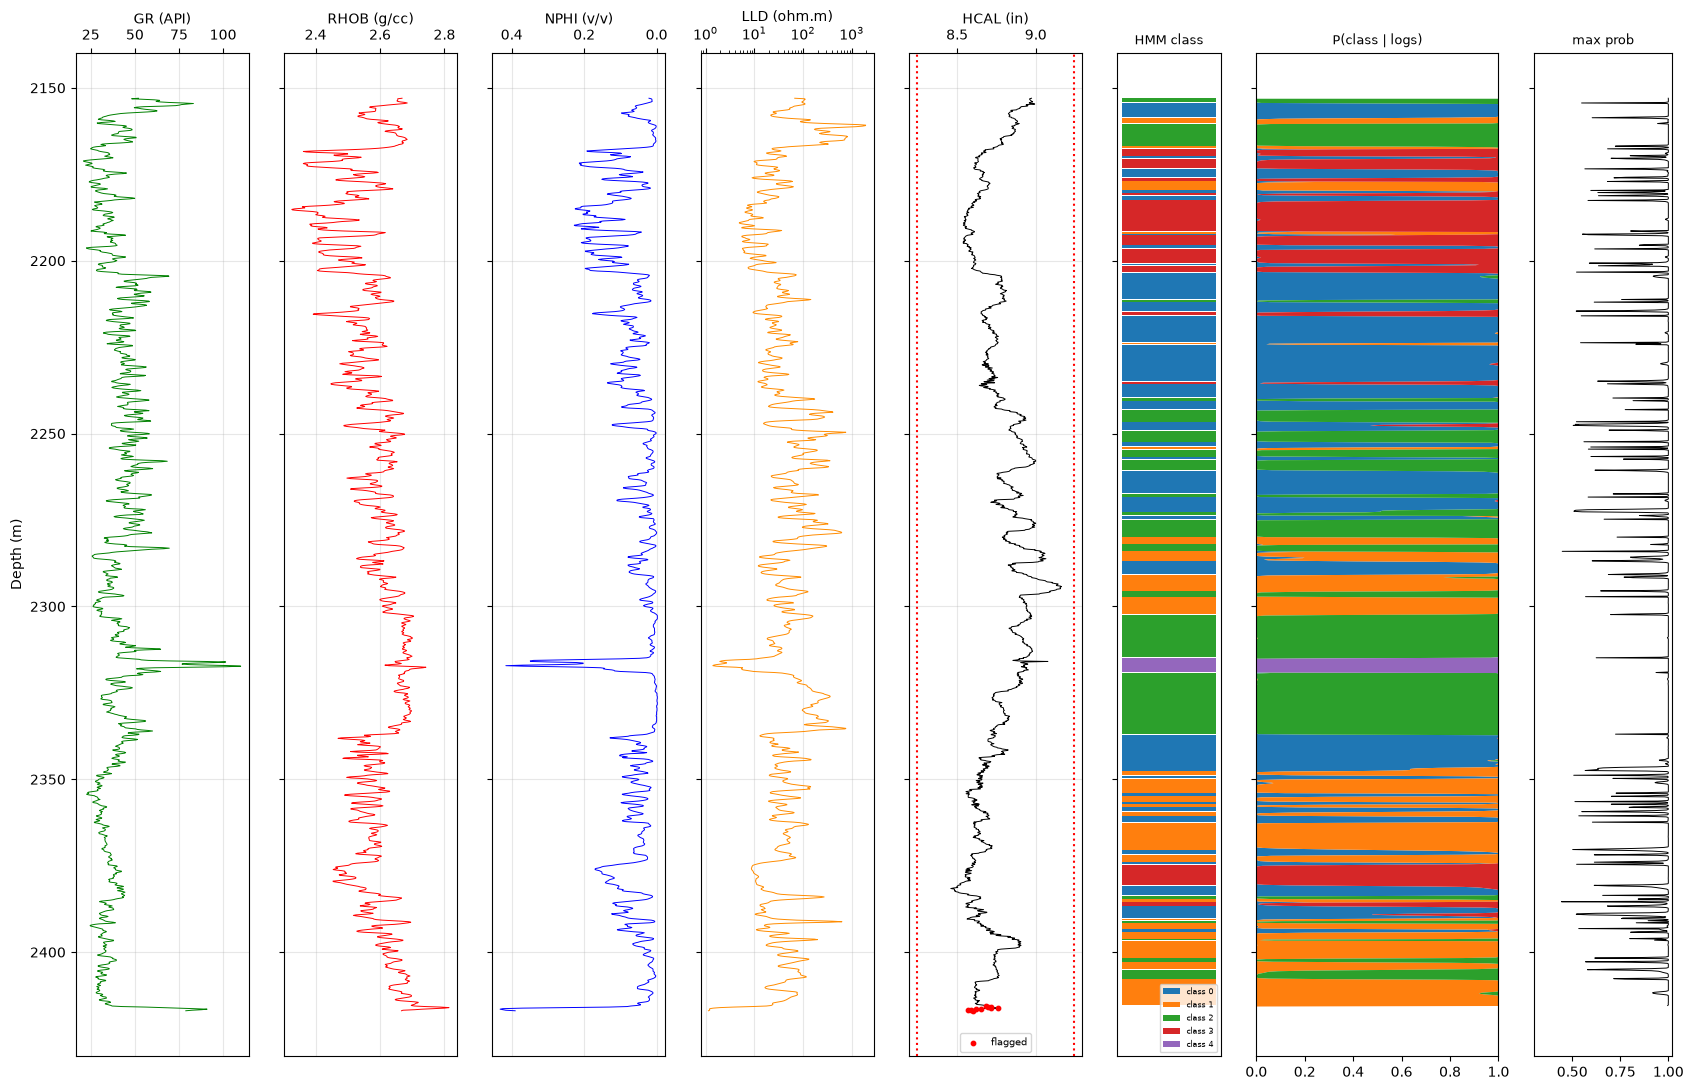

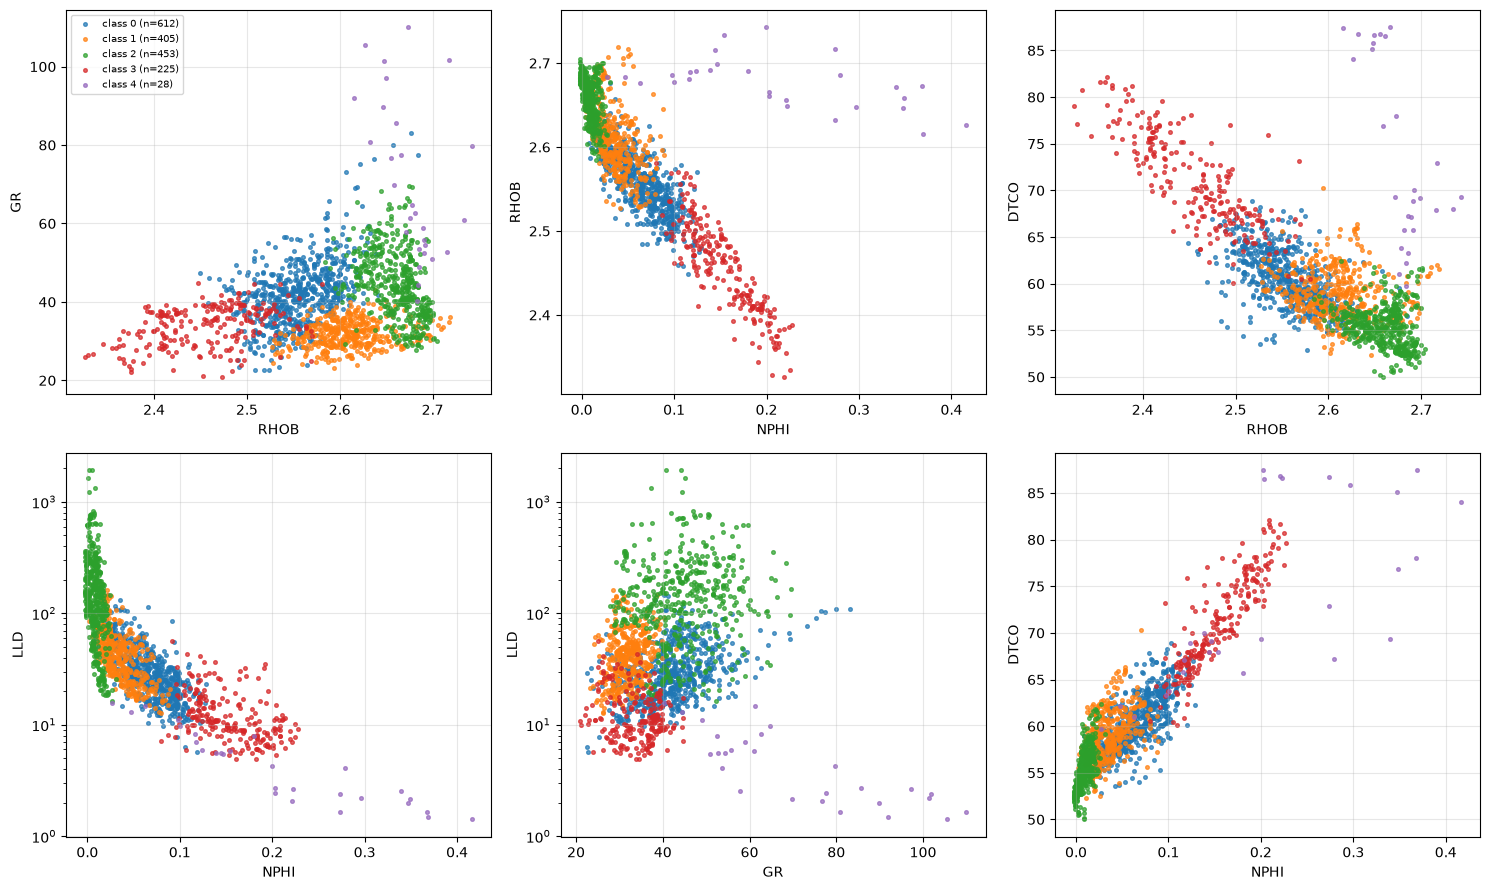

 Class   n  share %  Mean GR  Mean RHOB  Mean NPHI  Mean DTCO  Mean log10(LLD)  mean P(class)  n beds  median bed (m)  max bed (m)                   Response (tentative)
     0 612     35.5   42.211      2.556      0.066     60.484            1.471          0.956      32           1.600       10.668    GR mid, RHOB mid, NPHI mid, res mid
     1 405     23.5   31.899      2.609      0.035     59.004            1.617          0.960      24           1.829        7.925    GR low, RHOB mid, NPHI mid, res mid
     2 453     26.3   44.603      2.659      0.008     55.375            2.111          0.982      20           1.829       17.983  GR mid, RHOB high, NPHI low, res high
     3 225     13.1   33.860      2.456      0.153     71.004            1.062          0.969      12           2.057        8.992   GR low, RHOB low, NPHI high, res low
     4  28      1.6   70.984      2.677      0.208     73.675            0.615          0.987       1           4.267        4.267 GR high, RHOB high,

In [22]:
# ================= Step 7: required plots and outputs =================
from sklearn.metrics import adjusted_rand_score
K = 5
colsA = ["z_" + f for f in FEATURES_A]
cols = colsA
path_b, prob_b = decode(bay)               # Bayesian HMM: Viterbi path + smoothed P(state | all logs)
lab = relabel(path_b)                      # class 0 = biggest ... class 4 = smallest; -1 = flagged sample
prob_r = prob_b[:, order]                  # columns reordered to match the labels
df["hmm_class"] = lab
df["hmm_pmax"] = np.nanmax(prob_r, axis=1)
ok = (df.hmm_class >= 0).values
colors = plt.cm.tab10(np.arange(K))

# ---------- 7A. Input logs + QC flags + class sequence + class probabilities ----------
fig, ax = plt.subplots(1, 8, figsize=(17, 11), sharey=True,
                       gridspec_kw={"width_ratios": [1, 1, 1, 1, 1, .6, 1.4, .8]})
def track(a, col, color, label, log=False, invert=False):
    a.plot(df[col], df.DEPTH, color=color, lw=.7)
    if log: a.set_xscale("log")
    if invert: a.invert_xaxis()
    a.set_xlabel(label); a.xaxis.set_label_position("top"); a.xaxis.tick_top(); a.grid(alpha=.3)
track(ax[0], "GR", "green", "GR (API)")
track(ax[1], "RHOB", "red", "RHOB (g/cc)")
track(ax[2], "NPHI", "blue", "NPHI (v/v)", invert=True)
track(ax[3], "LLD", "darkorange", "LLD (ohm.m)", log=True)
track(ax[4], "HCAL", "black", "HCAL (in)")
bad = df[df.flag]                          # QC flags drawn on the caliper track
ax[4].scatter(bad.HCAL, bad.DEPTH, color="red", s=10, zorder=3, label="flagged"); ax[4].legend(fontsize=7)
ax[4].axvline(df.HCAL.median() + CALI_TOL_IN, color="red", ls=":")
ax[4].axvline(df.HCAL.median() - CALI_TOL_IN, color="red", ls=":")
for r in range(K):
    ax[5].fill_betweenx(df.DEPTH, 0, 1, where=(lab == r), color=colors[r], step="mid", linewidth=0, label=f"class {r}")
ax[5].set_xticks([]); ax[5].set_title("HMM class", fontsize=9); ax[5].legend(fontsize=6, loc="lower right")
cum = np.zeros(len(df)); P = np.nan_to_num(prob_r)
for r in range(K):
    ax[6].fill_betweenx(df.DEPTH, cum, cum + P[:, r], color=colors[r], linewidth=0); cum += P[:, r]
ax[6].set_xlim(0, 1); ax[6].set_title("P(class | logs)", fontsize=9)
ax[7].plot(df.hmm_pmax, df.DEPTH, color="black", lw=.7); ax[7].set_xlim(.3, 1.02); ax[7].set_title("max prob", fontsize=9)
ax[0].set_ylabel("Depth (m)"); ax[0].invert_yaxis()
plt.tight_layout(); plt.savefig("final_logs_classes.png", dpi=150); plt.show()

# ---------- 7B. Crossplots coloured by inferred class ----------
g = df[ok]
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
pairs = [("RHOB","GR"), ("NPHI","RHOB"), ("RHOB","DTCO"), ("NPHI","LLD"), ("GR","LLD"), ("NPHI","DTCO")]
for a, (x, y) in zip(axs.ravel(), pairs):
    for r in range(K):
        s = g[g.hmm_class == r]
        a.scatter(s[x], s[y], s=7, color=colors[r], label=f"class {r} (n={len(s)})", alpha=.7)
    if x == "LLD": a.set_xscale("log")
    if y == "LLD": a.set_yscale("log")
    a.set_xlabel(x); a.set_ylabel(y); a.grid(alpha=.3)
axs[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.savefig("crossplots_by_class.png", dpi=150); plt.show()

# ---------- 7C. Class summary table (original units) ----------
rl_all, cl_all = run_lengths(lab)
step_m = float(np.median(np.diff(df.DEPTH)))
rows = []
for r in range(K):
    s = g[g.hmm_class == r]
    runs_m = rl_all[cl_all == r] * step_m
    rows.append({"Class": r, "n": len(s), "share %": round(100 * len(s) / len(g), 1),
                 "Mean GR": s.GR.mean(), "Mean RHOB": s.RHOB.mean(), "Mean NPHI": s.NPHI.mean(),
                 "Mean DTCO": s.DTCO.mean(), "Mean log10(LLD)": s.logLLD.mean(),
                 "mean P(class)": s.hmm_pmax.mean(), "n beds": len(runs_m),
                 "median bed (m)": np.median(runs_m), "max bed (m)": runs_m.max()})
tab = pd.DataFrame(rows)
def level(v, m, sdv):
    z = (v - m) / sdv
    return "high" if z > .5 else "low" if z < -.5 else "mid"
tab["Response (tentative)"] = [
    f"GR {level(t['Mean GR'], g.GR.mean(), g.GR.std())}, RHOB {level(t['Mean RHOB'], g.RHOB.mean(), g.RHOB.std())}, "
    f"NPHI {level(t['Mean NPHI'], g.NPHI.mean(), g.NPHI.std())}, res {level(t['Mean log10(LLD)'], g.logLLD.mean(), g.logLLD.std())}"
    for _, t in tab.iterrows()]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(tab.round(3).to_string(index=False))
tab.round(3).to_csv("class_summary_table.csv", index=False)

print("\nThickest beds per class:")
starts = np.r_[0, np.where(np.diff(lab) != 0)[0] + 1]; ends = np.r_[starts[1:], len(lab)]
beds = pd.DataFrame({"class": lab[starts], "top": df.DEPTH.values[starts], "base": df.DEPTH.values[ends - 1]})
beds = beds[beds["class"] >= 0]; beds["thick_m"] = (beds.base - beds.top + step_m).round(1)
print(beds.sort_values("thick_m", ascending=False).groupby("class").head(2)
          .sort_values(["class", "thick_m"], ascending=[True, False]).to_string(index=False))

# ---------- 7D. Validation summary (collects Step 6 results) ----------
summary = pd.DataFrame({
    "Check": ["Held-out loglik best K (HMM)", "Held-out loglik best K (BGM)", "Bootstrap ARI (K=5)",
              "Weakest class Jaccard (mean)", "ARI GMM vs HMM", "Transition-prior sensitivity (runs<10)"],
    "Result": [f"K={int(val.loc[val.HMM_test.idxmax(), 'K'])} ({val.HMM_test.max():.2f})",
               f"K={int(val.loc[val.BGM_test.idxmax(), 'K'])} ({val.BGM_test.max():.2f})",
               f"{np.mean(ari):.2f} [{np.percentile(ari,5):.2f}, {np.percentile(ari,95):.2f}]",
               f"class {int(np.argmin(jac.mean(0)))}: {jac.mean(0).min():.2f}",
               f"{adjusted_rand_score(ref_lab, path_b[~df.flag.values]):.2f}",
               "39 -> 27 as stay pseudo-counts go 0 -> 1000 (from your Step 5 output)"]})
print("\n", summary.to_string(index=False))